# Complementariedad multimodal y análisis de errores

Clasificación morfológica binaria de galaxias MaNGA: `temprana` (0) vs `tardia` (1).

**Pregunta central:** ¿las modalidades (imagen RGB, espectro, poblaciones estelares STARLIGHT) contienen información predictiva *complementaria* que las arquitecturas actuales no aprovechan?

Este notebook **no entrena modelos**: analiza las `predictions.csv` ya generadas por la campaña de ablación (ver `notebook/julio/experiments/ANALISIS_EXPERIMENTOS_ABLACION.md`).

Distinguimos tres tipos de complementariedad, relacionados pero no equivalentes:

| Tipo | Significado | Dónde se evalúa |
|---|---|---|
| **Potencial** | una modalidad acierta donde otra falla | Secciones 4 y 5 |
| **Aprovechable** | una combinación *sin conocer la etiqueta* mejora resultados | Secciones 8 y 9 |
| **Física** | las discrepancias se asocian a propiedades astrofísicas | Secciones 6 y 7 |

**Índice:** 1 Configuración · 2 Auditoría · 3 Rendimiento individual · 4 Matrices de complementariedad · 5 Probabilidades y calibración · 6 Errores y propiedades físicas · 7 Galería · 8 Fusión tardía (validation) · 9 Incertidumbre (bootstrap) · 10 Síntesis.

> **Limitación metodológica global.** Los resultados de `test` ya se inspeccionaron durante el desarrollo del proyecto. Aquí `test` se usa solo de forma *descriptiva*; ningún peso, umbral o selección se decide con `test`. Hay una sola semilla y un solo split.

## 1. Configuración y descubrimiento de experimentos

Todo lo editable está en esta celda. Las rutas son relativas a la raíz del proyecto (se detecta buscando `data/galaxy_manifest.csv`).

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from scipy import stats
from sklearn.metrics import (average_precision_score, balanced_accuracy_score,
                             brier_score_loss, confusion_matrix, f1_score,
                             precision_recall_curve, precision_recall_fscore_support,
                             roc_auc_score, roc_curve)

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 200, "display.max_columns", 40, "display.float_format", "{:.4f}".format)


def find_root(start=None):
    start = Path(start or Path.cwd()).resolve()
    for p in [start, *start.parents]:
        if (p / "data" / "galaxy_manifest.csv").exists():
            return p
    raise FileNotFoundError("No se encontró la raíz del proyecto (data/galaxy_manifest.csv).")


ROOT = find_root()
EXP_DIR = ROOT / "models" / "experiments"
OUT_DIR = ROOT / "models" / "analysis" / "complementariedad_multimodal"
MANIFEST = ROOT / "data" / "galaxy_manifest.csv"
STARLIGHT_INDEX = ROOT / "data" / "processed" / "starlight" / "propiedades" / "indice.csv"

SEED = 42            # semilla global (bootstrap)
N_BOOT = 1000        # remuestreos bootstrap
EVAL_SPLIT = "test"          # split para análisis descriptivos (NO para elegir nada)
SELECT_SPLIT = "validation"  # único split usado para explorar/elegir pesos de fusión
SAVE_OUTPUTS = True  # False: no escribe tablas ni figuras

# Mapa editable: clave corta -> (carpeta del experimento, nombre descriptivo)
MODELS = {
    "rgb_cnn":         ("experimento_binario_imagenes_cnn_gpu", "CNN RGB compacta"),
    "rgb_resnet":      ("imagenes_resnet18_fov", "ResNet-18 RGB"),
    "esp_fov":         ("espectros_fov_cnn1d", "CNN1D espectro FoV"),
    "esp_sl":          ("espectros_starlight_cnn1d", "CNN1D espectro STARLIGHT"),
    "esp_sl_attn":     ("espectros_starlight_cnn_attn_control", "CNN+atención espectro STARLIGHT"),
    "pob":             ("poblaciones_starlight_mlp", "MLP poblaciones SL"),
    "rgb_esp_fov":     ("multimodal_imagenes_espectros_fov_concat", "RGB + espectro FoV"),
    "rgb_pob":         ("multimodal_imagenes_poblaciones_starlight_concat", "RGB + poblaciones"),
    "rgb_esp_sl_pob":  ("multimodal_imagenes_espectros_poblaciones_starlight_concat", "RGB + esp. SL + pob."),
    "rgb_esp_sl":      ("multimodal_imagenes_espectros_starlight_concat", "RGB + espectro SL"),
    "esp_sl_pob":      ("multimodal_espectros_poblaciones_starlight_concat", "Esp. SL + poblaciones"),
}
NAMES = {k: v[1] for k, v in MODELS.items()}
UNIMODAL = ["rgb_cnn", "rgb_resnet", "esp_fov", "esp_sl", "esp_sl_attn", "pob"]
ESSENTIAL = ["rgb_resnet", "pob", "esp_fov", "esp_sl", "rgb_cnn"]  # sin ellos el análisis no corre
REF = "rgb_resnet"  # RGB de referencia: mismo ResNet-18 que la rama visual de las fusiones
PRIORITY_PAIRS = [("rgb_resnet", "pob"), ("rgb_resnet", "esp_fov"), ("rgb_resnet", "esp_sl"),
                  ("esp_fov", "pob"), ("rgb_resnet", "rgb_cnn"), ("rgb_resnet", "esp_sl_attn"),
                  ("esp_sl", "esp_sl_attn")]
SPLITS = ["train", "validation", "test"]

rng_global = np.random.default_rng(SEED)
if SAVE_OUTPUTS:
    (OUT_DIR / "figuras").mkdir(parents=True, exist_ok=True)


def save_fig(fig, name):
    if SAVE_OUTPUTS:
        fig.savefig(OUT_DIR / "figuras" / f"{name}.png", dpi=130, bbox_inches="tight")


def save_table(df, name, index=False):
    if SAVE_OUTPUTS:
        df.to_csv(OUT_DIR / f"{name}.csv", index=index)


# Descubrimiento: qué experimentos tienen predictions.csv
raw, skipped = {}, {}
for k, (folder, _) in MODELS.items():
    f = EXP_DIR / folder / "predictions.csv"
    if f.exists():
        raw[k] = pd.read_csv(f)
    else:
        skipped[k] = f"{folder}: sin predictions.csv" if (EXP_DIR / folder).exists() else f"{folder}: carpeta ausente"

missing = [k for k in ESSENTIAL if k not in raw]
assert not missing, f"Faltan modelos esenciales: {missing}"
print(f"Raíz: {ROOT}")
print(f"Experimentos cargados ({len(raw)}): {list(raw)}")
print("Omitidos:", skipped or "ninguno")
extra = sorted(p.name for p in EXP_DIR.iterdir() if p.is_dir()
               and p.name not in {v[0] for v in MODELS.values()})
print("Carpetas de experimentos no mapeadas:", extra or "ninguna")

Raíz: /home/albertor/Documents/deep_learning/repos/clasificacion-galaxias
Experimentos cargados (11): ['rgb_cnn', 'rgb_resnet', 'esp_fov', 'esp_sl', 'esp_sl_attn', 'pob', 'rgb_esp_fov', 'rgb_pob', 'rgb_esp_sl_pob', 'rgb_esp_sl', 'esp_sl_pob']
Omitidos: ninguno
Carpetas de experimentos no mapeadas: ['espectros_starlight_cnn_bigru', 'espectros_starlight_patch_bigru', 'experimento_binario_imagenes_cnn', 'multimodal_imagenes_espectros_starlight_cnnattn_fusion', 'multimodal_imagenes_espectros_starlight_cnnattn_image_only_control']


## 2. Auditoría de predicciones y alineación de galaxias

**Pregunta:** ¿podemos comparar los modelos galaxia a galaxia sin sorpresas?
**Método:** validar esquema y consistencia de cada CSV, verificar que `y_proba` es P(tardía) y comparar cohortes por `name` + `split` (nunca por posición de fila).
**Intuición:** si dos modelos no evaluaron exactamente las mismas galaxias, una comparación pareada mezclaría diferencias de muestra con diferencias de modelo.

In [2]:
EXPECTED = ["name", "split", "label", "y_true", "y_proba", "y_pred", "pred_label", "correct"]
rows = []
for k, d in raw.items():
    val = d[d.split == "validation"]
    rows.append({
        "modelo": k,
        "filas": len(d),
        "esquema_ok": list(d.columns) == EXPECTED,
        "duplicados(name,split)": int(d.duplicated(["name", "split"]).sum()),
        "nulos": int(d[EXPECTED].isna().sum().sum()),
        "label==y_true": bool(((d.label == "tardia").astype(int) == d.y_true).all()),
        "correct==(y_pred==y_true)": bool((d.correct == (d.y_pred == d.y_true)).all()),
        "y_pred==(proba>=0.5)": float((d.y_pred == (d.y_proba >= 0.5)).mean()),
        "pred_label coherente": bool(((d.pred_label == "tardia").astype(int) == d.y_pred).all()),
        "proba en [0,1]": bool(d.y_proba.between(0, 1).all()),
        "media proba tardia-temprana": d.groupby("y_true").y_proba.mean().diff().iloc[-1],
        "AUC val (P=tardía)": roc_auc_score(val.y_true, val.y_proba),
    })
audit = pd.DataFrame(rows).set_index("modelo")
display(audit)

# Cohortes por split
keys = {k: {s: set(d.loc[d.split == s, "name"]) for s in SPLITS} for k, d in raw.items()}
cohort = pd.DataFrame({s: {k: len(keys[k][s]) for k in keys} for s in SPLITS})
cohort["union_vs_interseccion"] = [
    "iguales" if all(keys[k][s] == keys[REF][s] for s in SPLITS) else "DIFIEREN" for k in cohort.index]
display(cohort)
inter = {s: set.intersection(*[keys[k][s] for k in keys]) for s in SPLITS}
union = {s: set.union(*[keys[k][s] for k in keys]) for s in SPLITS}
print("Intersección / unión por split:", {s: (len(inter[s]), len(union[s])) for s in SPLITS})
leak = {a + "&" + b: len(inter[a] & inter[b]) for a, b in [("train", "validation"), ("train", "test"), ("validation", "test")]}
print("Galaxias en más de un split (debe ser 0):", leak)

# Tabla ancha por join explícito (name, split); y_true y label se verifican entre modelos
wide = None
for k, d in raw.items():
    t = d[["name", "split", "label", "y_true", "y_proba", "y_pred"]].rename(
        columns={"y_proba": f"p_{k}", "y_pred": f"pred_{k}", "y_true": f"yt_{k}", "label": f"lab_{k}"})
    wide = t if wide is None else wide.merge(t, on=["name", "split"], how="inner", validate="one_to_one")
n_dropped = {s: len(union[s]) - int((wide.split == s).sum()) for s in SPLITS}
assert all(v == 0 for v in n_dropped.values()), f"El inner join excluye galaxias: {n_dropped}"
yt_cols = [c for c in wide if c.startswith("yt_")]
lab_cols = [c for c in wide if c.startswith("lab_")]
assert (wide[yt_cols].nunique(axis=1) == 1).all() and (wide[lab_cols].nunique(axis=1) == 1).all(), \
    "Etiquetas inconsistentes entre modelos"
wide["y_true"], wide["label"] = wide[yt_cols[0]], wide[lab_cols[0]]
wide = wide.drop(columns=yt_cols + lab_cols)
for k in raw:
    wide[f"ok_{k}"] = wide[f"pred_{k}"] == wide["y_true"]

# Consistencia con el manifest
manifest = pd.read_csv(MANIFEST)
assert manifest.name.is_unique
chk = wide.merge(manifest[["name", "label"]], on="name", how="left", suffixes=("", "_manifest"))
print(f"Galaxias sin entrada en manifest: {int(chk.label_manifest.isna().sum())} | "
      f"etiquetas distintas al manifest: {int((chk.label != chk.label_manifest).sum())}")
print("Tabla ancha:", wide.shape, "| sin exclusiones (inner join == unión en todos los splits)")

,filas,esquema_ok,"duplicados(name,split)",nulos,label==y_true,correct==(y_pred==y_true),y_pred==(proba>=0.5),pred_label coherente,"proba en [0,1]",media proba tardia-temprana,AUC val (P=tardía)
modelo,,,,,,,,,,,
rgb_cnn,9351,True,0,0,True,True,1.0000,True,True,0.7018,0.9587
rgb_resnet,9351,True,0,0,True,True,1.0000,True,True,0.7631,0.9644
esp_fov,9351,True,0,0,True,True,1.0000,True,True,0.3778,0.8415
esp_sl,9351,True,0,0,True,True,1.0000,True,True,0.3721,0.8482
esp_sl_attn,9351,True,0,0,True,True,1.0000,True,True,0.4884,0.8985
pob,9351,True,0,0,True,True,1.0000,True,True,0.4917,0.8899
rgb_esp_fov,9351,True,0,0,True,True,1.0000,True,True,0.6836,0.9643
rgb_pob,9351,True,0,0,True,True,1.0000,True,True,0.7821,0.9629
rgb_esp_sl_pob,9351,True,0,0,True,True,1.0000,True,True,0.7647,0.9644


,train,validation,test,union_vs_interseccion
rgb_cnn,6545,1403,1403,iguales
rgb_resnet,6545,1403,1403,iguales
esp_fov,6545,1403,1403,iguales
esp_sl,6545,1403,1403,iguales
esp_sl_attn,6545,1403,1403,iguales
pob,6545,1403,1403,iguales
rgb_esp_fov,6545,1403,1403,iguales
rgb_pob,6545,1403,1403,iguales
rgb_esp_sl_pob,6545,1403,1403,iguales
rgb_esp_sl,6545,1403,1403,iguales


Intersección / unión por split: {'train': (6545, 6545), 'validation': (1403, 1403), 'test': (1403, 1403)}
Galaxias en más de un split (debe ser 0): {'train&validation': 0, 'train&test': 0, 'validation&test': 0}
Galaxias sin entrada en manifest: 0 | etiquetas distintas al manifest: 0
Tabla ancha: (9351, 37) | sin exclusiones (inner join == unión en todos los splits)


**Lectura automática de la auditoría.**

In [3]:
ok_all = audit[["esquema_ok", "label==y_true", "correct==(y_pred==y_true)", "pred_label coherente", "proba en [0,1]"]].all().all()
print(f"- Esquema/etiquetas/`correct`/rango de probabilidades consistentes en los {len(raw)} experimentos: {ok_all}.")
print(f"- Umbral implícito 0.5 en `y_pred`: coincidencia mínima {audit['y_pred==(proba>=0.5)'].min():.4f}.")
print(f"- `y_proba` es P(tardía): la media es mayor en tardías que en tempranas en {int((audit['media proba tardia-temprana'] > 0).sum())}/{len(audit)} modelos.")
print(f"- Cohortes idénticas entre modelos: {(cohort.union_vs_interseccion == 'iguales').all()}; "
      f"N por split = { {s: len(inter[s]) for s in SPLITS} }.")
print(f"- Duplicados totales: {int(audit['duplicados(name,split)'].sum())}; nulos totales: {int(audit['nulos'].sum())}.")
print("- `rgb_cnn` usa la corrida GPU (la corrida CPU `experimento_binario_imagenes_cnn` no tiene predictions.csv).")

- Esquema/etiquetas/`correct`/rango de probabilidades consistentes en los 11 experimentos: True.
- Umbral implícito 0.5 en `y_pred`: coincidencia mínima 1.0000.
- `y_proba` es P(tardía): la media es mayor en tardías que en tempranas en 11/11 modelos.
- Cohortes idénticas entre modelos: True; N por split = {'train': 6545, 'validation': 1403, 'test': 1403}.
- Duplicados totales: 0; nulos totales: 0.
- `rgb_cnn` usa la corrida GPU (la corrida CPU `experimento_binario_imagenes_cnn` no tiene predictions.csv).


## 3. Rendimiento individual de las modalidades

**Pregunta:** ¿qué tan bien funciona cada modalidad y qué errores comete?

**Métricas independientes del umbral:** ROC-AUC (probabilidad de que una tardía aleatoria reciba mayor P que una temprana aleatoria) y *average precision*. Miden el *ranking*.
**Dependientes del umbral (0.5):** accuracy, macro-F1, balanced accuracy, precision/recall por clase, matriz de confusión. Dos modelos con el mismo ranking pueden tener accuracy muy distinta según su punto de operación.
**Brier score:** error cuadrático medio de la probabilidad (menor es mejor); mezcla discriminación y calibración.

La tabla se reporta en `validation` y `test` **solo para describir**, no para reelegir el mejor modelo.

In [4]:
def metrics_row(y, p, pred):
    y, p, pred = np.asarray(y), np.asarray(p), np.asarray(pred)
    pr, rc, _, _ = precision_recall_fscore_support(y, pred, labels=[0, 1], zero_division=0)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return {"n": len(y), "roc_auc": roc_auc_score(y, p), "avg_precision": average_precision_score(y, p),
            "accuracy": (y == pred).mean(), "macro_f1": f1_score(y, pred, average="macro"),
            "balanced_acc": balanced_accuracy_score(y, pred),
            "precision_temprana": pr[0], "recall_temprana": rc[0], "precision_tardia": pr[1], "recall_tardia": rc[1],
            "TN": tn, "FP": fp, "FN": fn, "TP": tp, "brier": brier_score_loss(y, p)}


def split_df(split):
    return wide[wide.split == split].reset_index(drop=True)


metric_rows = []
for s in SPLITS:
    d = split_df(s)
    for k in raw:
        metric_rows.append({"split": s, "modelo": k, "nombre": NAMES[k], "tipo": "unimodal" if k in UNIMODAL else "multimodal",
                            **metrics_row(d.y_true, d[f"p_{k}"], d[f"pred_{k}"])})
metrics_all = pd.DataFrame(metric_rows)
save_table(metrics_all, "metricas_modelos")
cols = ["nombre", "n", "roc_auc", "avg_precision", "accuracy", "macro_f1", "balanced_acc",
        "precision_temprana", "recall_temprana", "precision_tardia", "recall_tardia", "TN", "FP", "FN", "TP", "brier"]
print(f"Modelos unimodales — {EVAL_SPLIT} (matriz de confusión: TN,FP,FN,TP con tardía = positivo)")
display(metrics_all[(metrics_all.split == EVAL_SPLIT) & metrics_all.modelo.isin(UNIMODAL)].set_index("modelo")[cols])
print("Modelos multimodales — test (referencia)")
display(metrics_all[(metrics_all.split == EVAL_SPLIT) & ~metrics_all.modelo.isin(UNIMODAL)].set_index("modelo")[cols])

Modelos unimodales — test (matriz de confusión: TN,FP,FN,TP con tardía = positivo)


,nombre,n,roc_auc,avg_precision,accuracy,macro_f1,balanced_acc,precision_temprana,recall_temprana,precision_tardia,recall_tardia,TN,FP,FN,TP,brier
modelo,,,,,,,,,,,,,,,,
rgb_cnn,CNN RGB compacta,1403,0.9623,0.9783,0.9009,0.8954,0.8992,0.8517,0.8920,0.9329,0.9063,471,57,82,793,0.0724
rgb_resnet,ResNet-18 RGB,1403,0.9633,0.9788,0.8881,0.8812,0.8825,0.8454,0.8598,0.9145,0.9051,454,74,83,792,0.0772
esp_fov,CNN1D espectro FoV,1403,0.8572,0.9069,0.7947,0.7771,0.7723,0.7500,0.6818,0.8180,0.8629,360,168,120,755,0.1474
esp_sl,CNN1D espectro STARLIGHT,1403,0.8642,0.9163,0.7890,0.7666,0.7588,0.7636,0.6364,0.8006,0.8811,336,192,104,771,0.1470
esp_sl_attn,CNN+atención espectro STARLIGHT,1403,0.9066,0.9404,0.8418,0.8329,0.8360,0.7772,0.8125,0.8837,0.8594,429,99,123,752,0.1171
pob,MLP poblaciones SL,1403,0.8949,0.9343,0.8375,0.8279,0.8299,0.7757,0.7992,0.8766,0.8606,422,106,122,753,0.1216


Modelos multimodales — test (referencia)


,nombre,n,roc_auc,avg_precision,accuracy,macro_f1,balanced_acc,precision_temprana,recall_temprana,precision_tardia,recall_tardia,TN,FP,FN,TP,brier
modelo,,,,,,,,,,,,,,,,
rgb_esp_fov,RGB + espectro FoV,1403,0.9635,0.9799,0.8874,0.8794,0.8774,0.8599,0.8371,0.9033,0.9177,442,86,72,803,0.0746
rgb_pob,RGB + poblaciones,1403,0.9639,0.9785,0.8988,0.8924,0.8929,0.8628,0.8693,0.9208,0.9166,459,69,73,802,0.0738
rgb_esp_sl_pob,RGB + esp. SL + pob.,1403,0.9650,0.9799,0.8895,0.8836,0.8881,0.8336,0.8826,0.9265,0.8937,466,62,93,782,0.0753
rgb_esp_sl,RGB + espectro SL,1403,0.9632,0.9796,0.8931,0.8875,0.8925,0.8363,0.8902,0.9310,0.8949,470,58,92,783,0.0751
esp_sl_pob,Esp. SL + poblaciones,1403,0.8960,0.9348,0.8346,0.8251,0.8276,0.7701,0.7992,0.8760,0.8560,422,106,126,749,0.1214


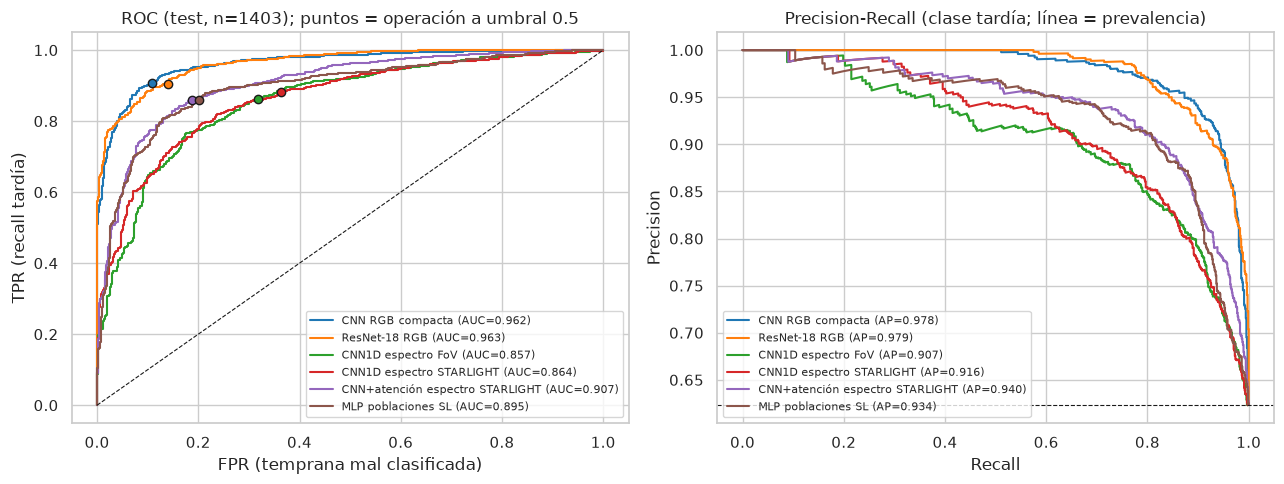

In [5]:
dte = split_df(EVAL_SPLIT)
palette = dict(zip(UNIMODAL, sns.color_palette("tab10", len(UNIMODAL))))
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for k in UNIMODAL:
    y, p = dte.y_true, dte[f"p_{k}"]
    fpr, tpr, _ = roc_curve(y, p)
    ax[0].plot(fpr, tpr, color=palette[k], label=f"{NAMES[k]} (AUC={roc_auc_score(y, p):.3f})")
    m = metrics_all[(metrics_all.split == EVAL_SPLIT) & (metrics_all.modelo == k)].iloc[0]
    ax[0].scatter(m.FP / (m.FP + m.TN), m.recall_tardia, color=palette[k], marker="o", edgecolor="k", zorder=5)
    pr, rc, _ = precision_recall_curve(y, p)
    ax[1].plot(rc, pr, color=palette[k], label=f"{NAMES[k]} (AP={average_precision_score(y, p):.3f})")
ax[0].plot([0, 1], [0, 1], "k--", lw=0.8)
ax[0].set(title=f"ROC ({EVAL_SPLIT}, n={len(dte)}); puntos = operación a umbral 0.5", xlabel="FPR (temprana mal clasificada)", ylabel="TPR (recall tardía)")
ax[1].axhline(dte.y_true.mean(), color="k", ls="--", lw=0.8)
ax[1].set(title="Precision-Recall (clase tardía; línea = prevalencia)", xlabel="Recall", ylabel="Precision")
ax[0].legend(loc="lower right", fontsize=8)
ax[1].legend(loc="lower left", fontsize=8)
plt.tight_layout()
save_fig(fig, "A_roc_pr_unimodales")
plt.show()

In [6]:
mt = metrics_all[(metrics_all.split == EVAL_SPLIT) & metrics_all.modelo.isin(UNIMODAL)].set_index("modelo")
best, worst = mt.roc_auc.idxmax(), mt.roc_auc.idxmin()
print(f"- Ranking por AUC ({EVAL_SPLIT}, solo descriptivo): " + " > ".join(f"{NAMES[k]} ({mt.loc[k, 'roc_auc']:.3f})" for k in mt.roc_auc.sort_values(ascending=False).index))
print(f"- Sesgo de umbral: recall de temprana va de {mt.recall_temprana.min():.3f} ({NAMES[mt.recall_temprana.idxmin()]}) a {mt.recall_temprana.max():.3f} ({NAMES[mt.recall_temprana.idxmax()]}).")
print(f"- Las dos RGB difieren {abs(mt.loc['rgb_cnn', 'roc_auc'] - mt.loc['rgb_resnet', 'roc_auc']):.4f} en AUC pero {abs(mt.loc['rgb_cnn', 'balanced_acc'] - mt.loc['rgb_resnet', 'balanced_acc']):.4f} en balanced accuracy y "
      f"{abs(mt.loc['rgb_cnn', 'recall_tardia'] - mt.loc['rgb_resnet', 'recall_tardia']):.3f} en recall de tardía: parte de la diferencia es punto de operación, no ranking.")
print("- Recall de tardía > recall de temprana en todos los modelos:", bool((mt.recall_tardia > mt.recall_temprana).all()), "(se favorece la clase mayoritaria).")

- Ranking por AUC (test, solo descriptivo): ResNet-18 RGB (0.963) > CNN RGB compacta (0.962) > CNN+atención espectro STARLIGHT (0.907) > MLP poblaciones SL (0.895) > CNN1D espectro STARLIGHT (0.864) > CNN1D espectro FoV (0.857)
- Sesgo de umbral: recall de temprana va de 0.636 (CNN1D espectro STARLIGHT) a 0.892 (CNN RGB compacta).
- Las dos RGB difieren 0.0009 en AUC pero 0.0167 en balanced accuracy y 0.001 en recall de tardía: parte de la diferencia es punto de operación, no ranking.
- Recall de tardía > recall de temprana en todos los modelos: True (se favorece la clase mayoritaria).


## 4. Matrices de complementariedad y tasas de rescate

**Pregunta:** ¿cuántas galaxias clasifica bien una modalidad cuando otra falla?

Para cada pareja (A, B) se construye la tabla de contingencia acierta/falla y se calculan:

- **Tasa de rescate B→A** = N(A falla y B acierta) / N(A falla): fracción de los errores de A que B resuelve. **No es simétrica:** rescatar A con B ≠ rescatar B con A.
- **Desacuerdo** = N(pred_A ≠ pred_B) / N.
- **Cobertura del oráculo** = N(A acierta o B acierta) / N.
- **Jaccard de errores** = |errores comunes| / |errores de A ∪ errores de B| (1 = mismos errores; 0 = disjuntos).

> ⚠️ **El oráculo conoce implícitamente cuál modelo acierta.** Es un límite superior *retrospectivo*; no es un sistema implementable ni evidencia de que una fusión entrenable alcance ese rendimiento. Sirve solo para medir la complementariedad *potencial*.

In [7]:
def pair_stats(d, a, b):
    oa, ob = d[f"ok_{a}"].to_numpy(), d[f"ok_{b}"].to_numpy()
    n = len(d)
    both, only_a, only_b, neither = (oa & ob).sum(), (oa & ~ob).sum(), (~oa & ob).sum(), (~oa & ~ob).sum()
    err_a, err_b = only_b + neither, only_a + neither
    div = lambda x, y: x / y if y else np.nan
    return {"A": a, "B": b, "n": n, "ambos_aciertan": both, "solo_A_acierta": only_a, "solo_B_acierta": only_b,
            "ambos_fallan": neither, "errores_A": err_a, "errores_B": err_b,
            "rescate_B_a_A": div(only_b, err_a), "rescate_A_a_B": div(only_a, err_b),
            "desacuerdo": (d[f"pred_{a}"] != d[f"pred_{b}"]).mean(), "oraculo_acc": (n - neither) / n,
            "acc_A": oa.mean(), "acc_B": ob.mean(), "ganancia_oraculo_vs_mejor": (n - neither) / n - max(oa.mean(), ob.mean()),
            "jaccard_errores": div(neither, err_a + err_b - neither),
            "pct_errores_A_compartidos": div(neither, err_a), "pct_errores_B_compartidos": div(neither, err_b)}


all_pairs = [(a, b) for i, a in enumerate(UNIMODAL) for b in UNIMODAL[i + 1:]]
pair_rows = []
for s in ["validation", "test"]:
    d = split_df(s)
    prio = set(PRIORITY_PAIRS)
    for a, b in dict.fromkeys(PRIORITY_PAIRS + all_pairs):
        pair_rows.append({"split": s, "prioritaria": (a, b) in prio, **pair_stats(d, a, b)})
pairs = pd.DataFrame(pair_rows)
save_table(pairs, "matrices_complementariedad")
rescue_cols = ["split", "A", "B", "n", "rescate_B_a_A", "rescate_A_a_B", "errores_A", "errores_B", "ambos_fallan"]
save_table(pairs[rescue_cols + ["desacuerdo", "oraculo_acc", "jaccard_errores"]], "tasas_rescate")

pt = pairs[(pairs.split == EVAL_SPLIT) & pairs.prioritaria]
print(f"Parejas prioritarias — {EVAL_SPLIT} (n compartido = {len(dte)})")
display(pt.drop(columns=["split", "prioritaria"]).set_index(["A", "B"]))

Parejas prioritarias — test (n compartido = 1403)


n  ambos_aciertan  solo_A_acierta  solo_B_acierta  ambos_fallan  errores_A  errores_B  rescate_B_a_A  rescate_A_a_B  desacuerdo  oraculo_acc  acc_A  acc_B  \
A          B                                                                                                                                                                            
rgb_resnet pob          1403            1094             152              81            76        157        228         0.5159         0.6667      0.1661       0.9458 0.8881 0.8375   
           esp_fov      1403            1035             211              80            77        157        288         0.5096         0.7326      0.2074       0.9451 0.8881 0.7947   
           esp_sl       1403            1026             220              81            76        157        296         0.5159         0.7432      0.2145       0.9458 0.8881 0.7890   
esp_fov    pob          1403            1068              47             107           181        288        228         0.3715         0.2061      0.1098       0.8710 0.7947 0.8375   
rgb_resnet rgb_cnn      1403            1209              37              55           102        157        139         0.3503         0.2662      0.0656       0.9273 0.8881 0.9009   
           esp_sl_attn  1403            1103             143              78            79        157        222         0.4968         0.6441      0.1575       0.9437 0.8881 0.8418   
esp_sl     esp_sl_attn  1403            1051              56             130           166        296        222         0.4392         0.2523      0.1326       0.8817 0.7890 0.8418   

                        ganancia_oraculo_vs_mejor  jaccard_errores  pct_errores_A_compartidos  pct_errores_B_compartidos  
A          B                                                                                                              
rgb_resnet pob                             0.0577           0.2460                     0.4841                     0.3333  
           esp_fov                         0.0570           0.2092                     0.4904                     0.2674  
           esp_sl                          0.0577           0.2016                     0.4841                     0.2568  
esp_fov    pob                             0.0335           0.5403                     0.6285                     0.7939  
rgb_resnet rgb_cnn                         0.0264           0.5258                     0.6497                     0.7338  
           esp_sl_attn                     0.0556           0.2633                     0.5032                     0.3559  
esp_sl     esp_sl_attn                     0.0399           0.4716                     0.5608                     0.7477

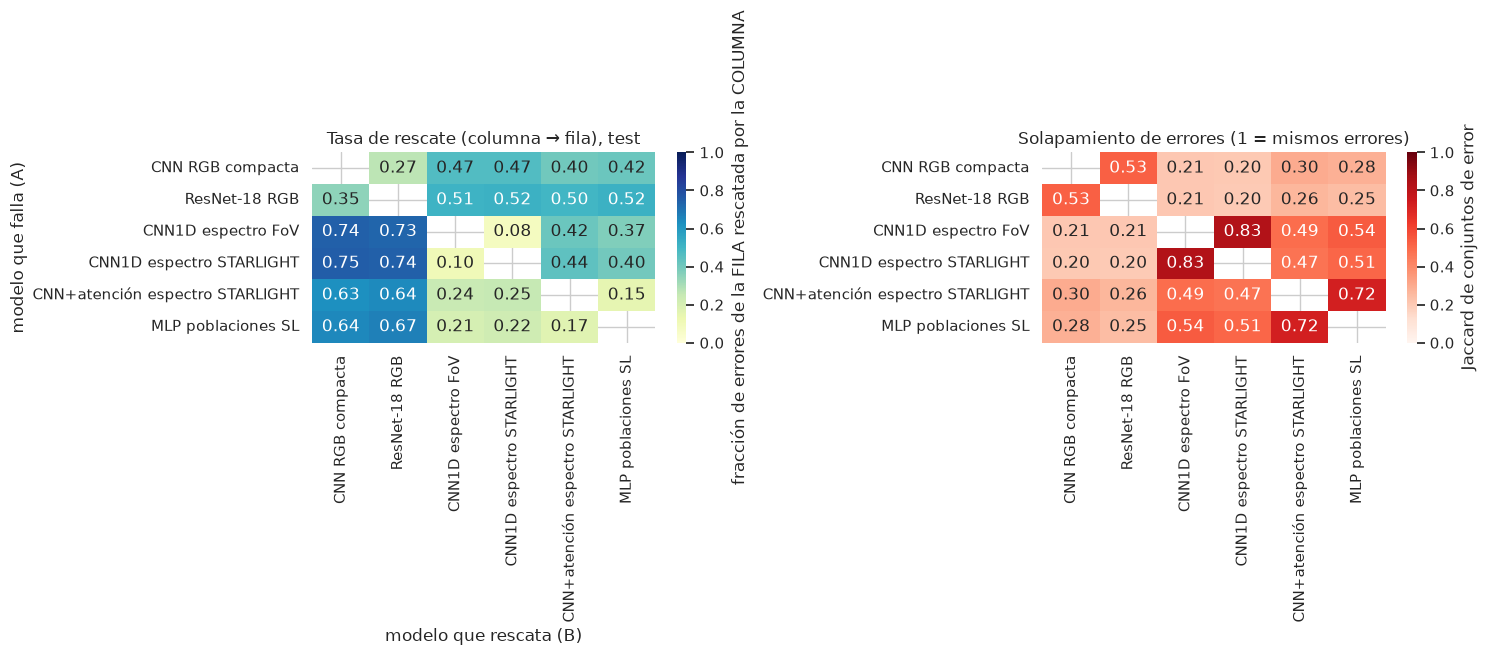

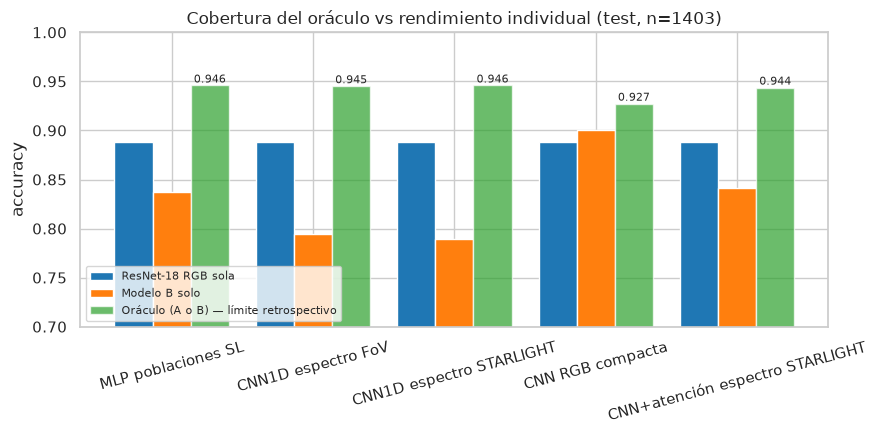

Errores de ResNet-18 RGB en test: 157 de 1403 (11.2%). Corregidos por ≥1 de ['pob', 'esp_fov', 'esp_sl', 'esp_sl_attn']: 64.3%; por las 4 a la vez: 38.2%.


In [8]:
def sym_matrix(col_fn, models):
    M = pd.DataFrame(np.nan, index=models, columns=models)
    for a in models:
        for b in models:
            if a != b:
                M.loc[a, b] = col_fn(a, b)
    return M


pe = {(r.A, r.B): r for r in pairs[pairs.split == EVAL_SPLIT].itertuples()}
rescue_M = sym_matrix(lambda a, b: pe[(a, b)].rescate_B_a_A if (a, b) in pe else pe[(b, a)].rescate_A_a_B, UNIMODAL)
jac_M = sym_matrix(lambda a, b: (pe[(a, b)] if (a, b) in pe else pe[(b, a)]).jaccard_errores, UNIMODAL)
lab = [NAMES[k] for k in UNIMODAL]

fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
sns.heatmap(rescue_M.set_axis(lab, axis=0).set_axis(lab, axis=1), annot=True, fmt=".2f", cmap="YlGnBu", vmin=0, vmax=1, ax=ax[0],
            cbar_kws={"label": "fracción de errores de la FILA rescatada por la COLUMNA"})
ax[0].set_title(f"Tasa de rescate (columna → fila), {EVAL_SPLIT}")
ax[0].set_ylabel("modelo que falla (A)")
ax[0].set_xlabel("modelo que rescata (B)")
sns.heatmap(jac_M.set_axis(lab, axis=0).set_axis(lab, axis=1), annot=True, fmt=".2f", cmap="Reds", vmin=0, vmax=1, ax=ax[1],
            cbar_kws={"label": "Jaccard de conjuntos de error"})
ax[1].set_title("Solapamiento de errores (1 = mismos errores)")
plt.tight_layout()
save_fig(fig, "B_rescate_y_solapamiento")
plt.show()

# Cobertura del oráculo frente al rendimiento individual (A = RGB de referencia)
oc = pairs[(pairs.split == EVAL_SPLIT) & (pairs.A == REF)].set_index("B")
fig, ax = plt.subplots(figsize=(9, 4.5))
x = np.arange(len(oc))
ax.bar(x - 0.27, oc.acc_A, 0.27, label=f"{NAMES[REF]} sola", color="tab:blue")
ax.bar(x, oc.acc_B, 0.27, label="Modelo B solo", color="tab:orange")
ax.bar(x + 0.27, oc.oraculo_acc, 0.27, label="Oráculo (A o B) — límite retrospectivo", color="tab:green", alpha=0.7)
for i, (a, b, o) in enumerate(zip(oc.acc_A, oc.acc_B, oc.oraculo_acc)):
    ax.text(i + 0.27, o + 0.003, f"{o:.3f}", ha="center", fontsize=8)
ax.set_xticks(x, [NAMES[k] for k in oc.index], rotation=15)
ax.set_ylim(0.7, 1.0)
ax.set(ylabel="accuracy", title=f"Cobertura del oráculo vs rendimiento individual ({EVAL_SPLIT}, n={len(dte)})")
ax.legend(fontsize=8, loc="lower left")
plt.tight_layout()
save_fig(fig, "B_cobertura_oraculo")
plt.show()

# Errores del RGB de referencia y cuántos corrige al menos otra modalidad
others = ["pob", "esp_fov", "esp_sl", "esp_sl_attn"]
err_ref = dte[~dte[f"ok_{REF}"]]
any_resc = err_ref[[f"ok_{k}" for k in others]].any(axis=1).mean()
all_resc = err_ref[[f"ok_{k}" for k in others]].all(axis=1).mean()
print(f"Errores de {NAMES[REF]} en {EVAL_SPLIT}: {len(err_ref)} de {len(dte)} ({len(err_ref) / len(dte):.1%}). "
      f"Corregidos por ≥1 de {others}: {any_resc:.1%}; por las {len(others)} a la vez: {all_resc:.1%}.")

In [9]:
r = pairs[(pairs.split == EVAL_SPLIT) & (pairs.A == REF) & pairs.B.isin(others)].set_index("B")
print(f"- Modalidad que rescata más errores de {NAMES[REF]}: {NAMES[r.rescate_B_a_A.idxmax()]} ({r.rescate_B_a_A.max():.1%} de {int(r.loc[r.rescate_B_a_A.idxmax(), 'errores_A'])} errores).")
for k, row in r.iterrows():
    print(f"  · {NAMES[k]}: rescata {row.rescate_B_a_A:.1%} de los errores RGB; comparte {row.pct_errores_A_compartidos:.1%}; "
          f"oráculo {row.oraculo_acc:.3f} (+{row.ganancia_oraculo_vs_mejor:.3f} vs RGB sola); Jaccard {row.jaccard_errores:.2f}.")
rp = r.loc["pob"]
print(f"- Errores compartidos RGB∩poblaciones: {int(rp.ambos_fallan)} galaxias ({rp.pct_errores_B_compartidos:.1%} de los errores de poblaciones).")
vr = pairs[(pairs.split == "validation") & (pairs.A == REF) & (pairs.B == "pob")].iloc[0]
print(f"- Consistencia entre splits (RGB↔poblaciones): rescate B→A {vr.rescate_B_a_A:.1%} en validation vs {rp.rescate_B_a_A:.1%} en {EVAL_SPLIT}.")
print(f"- Referencia: si los errores fueran independientes, B rescataría ≈ acc_B = {rp.acc_B:.1%} de los errores de A; se observa {rp.rescate_B_a_A:.1%}.")
exp_shared = (1 - rp.acc_A) * (1 - rp.acc_B) * len(dte)
print(f"  Si los errores fueran independientes se esperarían ≈{exp_shared:.0f} errores compartidos; se observan {int(rp.ambos_fallan)} "
      f"({'más' if rp.ambos_fallan > exp_shared else 'menos'} → errores {'correlacionados (dificultad común)' if rp.ambos_fallan > exp_shared else 'más complementarios que el azar'}).")

- Modalidad que rescata más errores de ResNet-18 RGB: MLP poblaciones SL (51.6% de 157 errores).
  · MLP poblaciones SL: rescata 51.6% de los errores RGB; comparte 48.4%; oráculo 0.946 (+0.058 vs RGB sola); Jaccard 0.25.
  · CNN1D espectro FoV: rescata 51.0% de los errores RGB; comparte 49.0%; oráculo 0.945 (+0.057 vs RGB sola); Jaccard 0.21.
  · CNN1D espectro STARLIGHT: rescata 51.6% de los errores RGB; comparte 48.4%; oráculo 0.946 (+0.058 vs RGB sola); Jaccard 0.20.
  · CNN+atención espectro STARLIGHT: rescata 49.7% de los errores RGB; comparte 50.3%; oráculo 0.944 (+0.056 vs RGB sola); Jaccard 0.26.
- Errores compartidos RGB∩poblaciones: 76 galaxias (33.3% de los errores de poblaciones).
- Consistencia entre splits (RGB↔poblaciones): rescate B→A 56.2% en validation vs 51.6% en test.
- Referencia: si los errores fueran independientes, B rescataría ≈ acc_B = 83.7% de los errores de A; se observa 51.6%.
  Si los errores fueran independientes se esperarían ≈26 errores compartidos; se 

## 5. Desacuerdos, confianza y calibración

**Pregunta:** ¿los modelos discrepan solo en la clase final o también en su confianza?

- **|P_A − P_B|:** distancia entre probabilidades; revela desacuerdos "suaves" (0.45 vs 0.55) frente a duros (0.05 vs 0.95).
- **Reliability diagram:** si un modelo dice 0.8, ¿el 80 % de esas galaxias son realmente tardías? Una probabilidad extrema solo es "confianza" si el modelo está calibrado.
- **ECE (Expected Calibration Error):** promedio ponderado de |frecuencia observada − probabilidad media| por bin. **Limitación:** depende del número y tipo de bins y del tamaño de muestra; se muestra su sensibilidad.
- **Brier score:** error cuadrático de la probabilidad (ya reportado en la sección 3).

Tamaños de grupo: {'ambos_aciertan': 1094, 'solo_rgb': 152, 'solo_poblaciones': 81, 'ambos_fallan': 76}


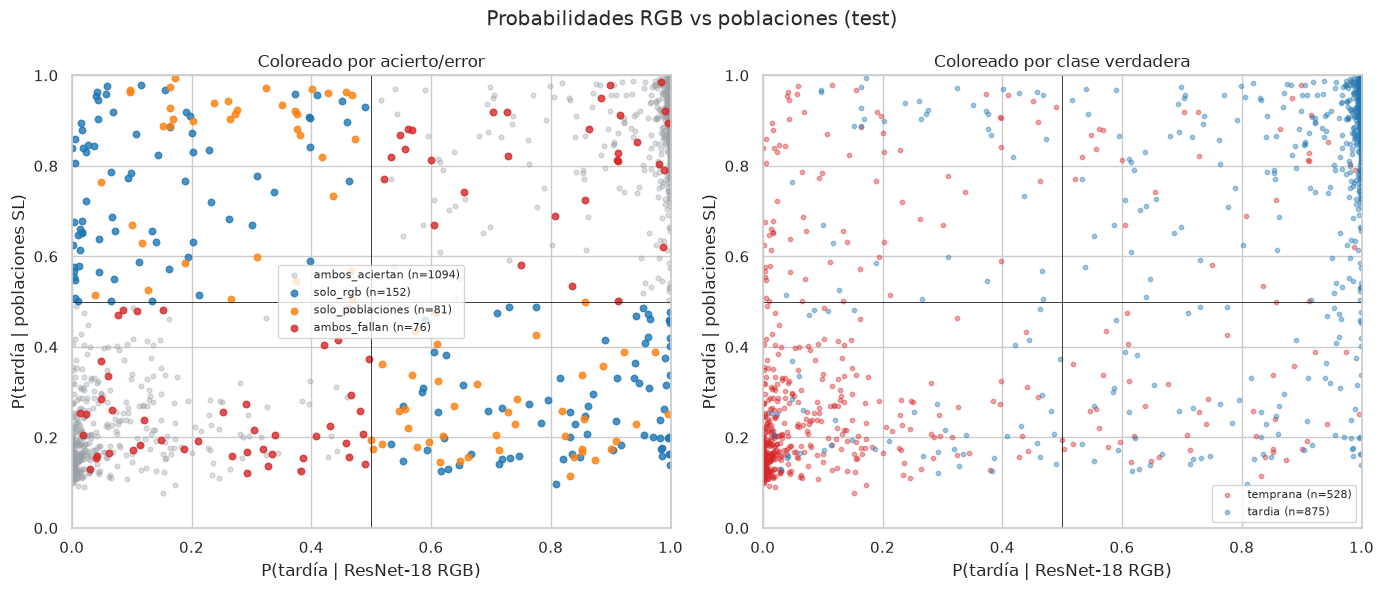

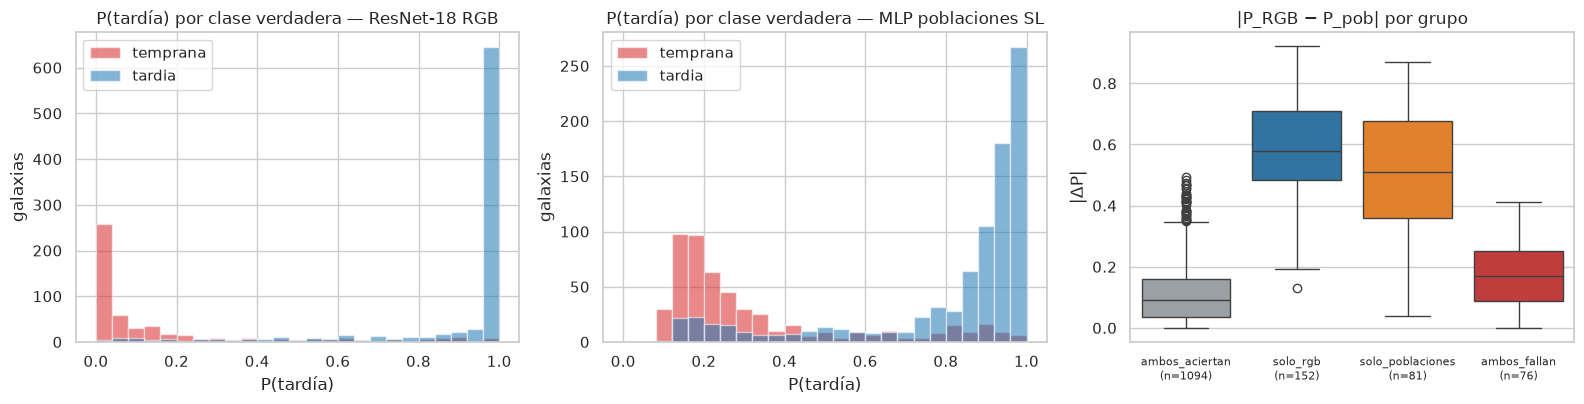

In [10]:
D = dte.copy()
D["grupo_rgb_pob"] = np.select(
    [D[f"ok_{REF}"] & D.ok_pob, D[f"ok_{REF}"] & ~D.ok_pob, ~D[f"ok_{REF}"] & D.ok_pob],
    ["ambos_aciertan", "solo_rgb", "solo_poblaciones"], default="ambos_fallan")
GROUP_ORDER = ["ambos_aciertan", "solo_rgb", "solo_poblaciones", "ambos_fallan"]
GROUP_COLORS = dict(zip(GROUP_ORDER, ["#9aa0a6", "#1f77b4", "#ff7f0e", "#d62728"]))
D["dp"] = (D[f"p_{REF}"] - D.p_pob).abs()
print("Tamaños de grupo:", D.grupo_rgb_pob.value_counts().reindex(GROUP_ORDER).to_dict())

fig, ax = plt.subplots(1, 2, figsize=(14, 6))
for g in GROUP_ORDER:
    s = D[D.grupo_rgb_pob == g]
    ax[0].scatter(s[f"p_{REF}"], s.p_pob, s=12 if g == "ambos_aciertan" else 22, alpha=0.35 if g == "ambos_aciertan" else 0.8,
                  color=GROUP_COLORS[g], label=f"{g} (n={len(s)})")
for k, c in zip([0, 1], ["tab:red", "tab:blue"]):
    s = D[D.y_true == k]
    ax[1].scatter(s[f"p_{REF}"], s.p_pob, s=10, alpha=0.4, color=c, label=["temprana", "tardia"][k] + f" (n={len(s)})")
for a in ax:
    a.axhline(0.5, color="k", lw=0.6)
    a.axvline(0.5, color="k", lw=0.6)
    a.set(xlabel=f"P(tardía | {NAMES[REF]})", ylabel="P(tardía | poblaciones SL)", xlim=(0, 1), ylim=(0, 1))
ax[0].set_title("Coloreado por acierto/error"); ax[1].set_title("Coloreado por clase verdadera")
ax[0].legend(fontsize=8); ax[1].legend(fontsize=8)
plt.suptitle(f"Probabilidades RGB vs poblaciones ({EVAL_SPLIT})")
plt.tight_layout()
save_fig(fig, "C_scatter_rgb_vs_poblaciones")
plt.show()

fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
for a, k in zip(ax[:2], [REF, "pob"]):
    for c, col in [(0, "tab:red"), (1, "tab:blue")]:
        a.hist(D.loc[D.y_true == c, f"p_{k}"], bins=25, range=(0, 1), alpha=0.55, color=col, label=["temprana", "tardia"][c])
    a.set(title=f"P(tardía) por clase verdadera — {NAMES[k]}", xlabel="P(tardía)", ylabel="galaxias")
    a.legend()
sns.boxplot(data=D, x="grupo_rgb_pob", y="dp", order=GROUP_ORDER, palette=GROUP_COLORS, hue="grupo_rgb_pob", legend=False, ax=ax[2])
ax[2].set(title="|P_RGB − P_pob| por grupo", xlabel="", ylabel="|ΔP|")
ax[2].set_xticks(range(4), [f"{g}\n(n={int((D.grupo_rgb_pob == g).sum())})" for g in GROUP_ORDER], fontsize=8)
plt.tight_layout()
save_fig(fig, "C_histogramas_y_delta")
plt.show()

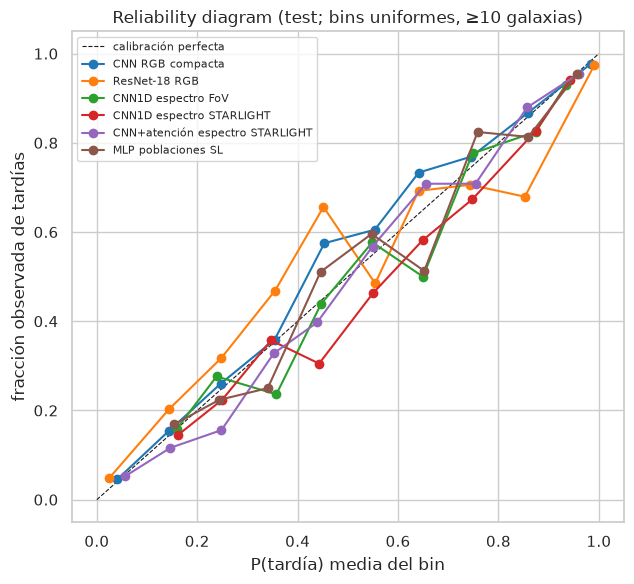

,Brier,ECE 5 bins,ECE 10 bins,ECE 15 bins,ECE 10 bins (cuantiles)
CNN RGB compacta,0.0724,0.0128,0.0138,0.0196,0.0159
ResNet-18 RGB,0.0772,0.0325,0.0376,0.0335,0.0300
CNN1D espectro FoV,0.1474,0.0215,0.0336,0.0351,0.0339
CNN1D espectro STARLIGHT,0.1470,0.0332,0.0370,0.0457,0.0471
CNN+atención espectro STARLIGHT,0.1171,0.0159,0.0243,0.0214,0.0194
MLP poblaciones SL,0.1216,0.0200,0.0270,0.0310,0.0173


In [11]:
def ece(y, p, bins=10, strategy="uniform"):
    y, p = np.asarray(y), np.asarray(p)
    edges = np.linspace(0, 1, bins + 1) if strategy == "uniform" else np.unique(np.quantile(p, np.linspace(0, 1, bins + 1)))
    b = np.clip(np.digitize(p, edges[1:-1]), 0, len(edges) - 2)
    return sum((b == i).mean() * abs(y[b == i].mean() - p[b == i].mean()) for i in range(len(edges) - 1) if (b == i).any())


fig, ax = plt.subplots(figsize=(6.5, 6))
ax.plot([0, 1], [0, 1], "k--", lw=0.8, label="calibración perfecta")
edges = np.linspace(0, 1, 11)
for k in UNIMODAL:
    p, y = D[f"p_{k}"].to_numpy(), D.y_true.to_numpy()
    b = np.clip(np.digitize(p, edges[1:-1]), 0, 9)
    pts = [(p[b == i].mean(), y[b == i].mean()) for i in range(10) if (b == i).sum() >= 10]
    ax.plot(*zip(*pts), marker="o", color=palette[k], label=NAMES[k])
ax.set(xlabel="P(tardía) media del bin", ylabel="fracción observada de tardías", title=f"Reliability diagram ({EVAL_SPLIT}; bins uniformes, ≥10 galaxias)")
ax.legend(fontsize=8)
plt.tight_layout()
save_fig(fig, "C_calibracion")
plt.show()

cal = pd.DataFrame({
    NAMES[k]: {"Brier": brier_score_loss(D.y_true, D[f"p_{k}"]),
               "ECE 5 bins": ece(D.y_true, D[f"p_{k}"], 5), "ECE 10 bins": ece(D.y_true, D[f"p_{k}"], 10),
               "ECE 15 bins": ece(D.y_true, D[f"p_{k}"], 15), "ECE 10 bins (cuantiles)": ece(D.y_true, D[f"p_{k}"], 10, "quantile")}
    for k in UNIMODAL}).T
display(cal)

In [12]:
# Casos de interés con criterios reproducibles (umbrales editables)
NEAR = 0.15     # "RGB cerca de 0.5": |P_rgb - 0.5| <= NEAR
CONF = 0.30     # "modalidad confiada": |P - 0.5| >= CONF
EXTREME = 0.40  # "muy confiada" (P <= 0.10 o >= 0.90)
conf_correct = lambda d, k: np.where(d.y_true == 1, d[f"p_{k}"], 1 - d[f"p_{k}"])  # P asignada a la clase verdadera
D["cc_rgb"], D["cc_pob"] = conf_correct(D, REF), conf_correct(D, "pob")
D["cc_esp_fov"] = conf_correct(D, "esp_fov")
pr_ = D[f"p_{REF}"]

masks = {
    "rgb_falla_pob_acierta": ~D[f"ok_{REF}"] & D.ok_pob,
    "rgb_acierta_pob_falla": D[f"ok_{REF}"] & ~D.ok_pob,
    "ambos_fallan": ~D[f"ok_{REF}"] & ~D.ok_pob,
    "contradictorias_confiadas": ((pr_ - 0.5).abs() >= EXTREME) & ((D.p_pob - 0.5).abs() >= EXTREME) & (D[f"pred_{REF}"] != D.pred_pob),
    "cerca_frontera_rgb": (pr_ - 0.5).abs() <= NEAR,
}
scores = {  # mayor = más interesante; criterio documentado
    "rgb_falla_pob_acierta": D.cc_pob - D.cc_rgb,
    "rgb_acierta_pob_falla": D.cc_rgb - D.cc_pob,
    "ambos_fallan": -(D.cc_rgb + D.cc_pob) / 2,
    "contradictorias_confiadas": D.dp,
    "cerca_frontera_rgb": -(pr_ - 0.5).abs(),
}
special = {
    f"RGB incierta (|P-0.5|≤{NEAR}) y poblaciones aciertan con |P-0.5|≥{CONF}": int((masks["cerca_frontera_rgb"] & D.ok_pob & ((D.p_pob - 0.5).abs() >= CONF)).sum()),
    f"Ambas muy confiadas (|P-0.5|≥{EXTREME}) y opuestas": int(masks["contradictorias_confiadas"].sum()),
    "RGB muy confiada (|P-0.5|≥0.40) y errónea": int(((pr_ - 0.5).abs() >= EXTREME).mul(~D[f"ok_{REF}"]).sum()),
}
print(pd.Series(special).to_string())

N_TOP = 30
disc = []
for g, m in masks.items():
    sel = D[m].assign(score=scores[g][m]).sort_values(["score", "name"], ascending=[False, True]).head(N_TOP)
    disc.append(sel.assign(grupo=g, rank=np.arange(1, len(sel) + 1), n_grupo=int(m.sum())))
disc = pd.concat(disc)
keep = ["grupo", "rank", "n_grupo", "name", "split", "label", "y_true", "grupo_rgb_pob", "score"] + \
       [c for c in D if c.startswith(("p_", "pred_"))]
disc = disc[keep].merge(manifest[["name", "Type", "Ttype", "LogMass", "nsa_z", "incl", "PETRO_TH90", "fov_0_path"]], on="name", how="left")
save_table(disc, "galaxias_discordantes")
print("Galaxias seleccionadas por grupo (top-30 por score; una galaxia puede estar en varios grupos):")
print(disc.groupby("grupo").agg(n_total_grupo=("n_grupo", "first"), n_guardadas=("name", "size")).to_string())

RGB incierta (|P-0.5|≤0.15) y poblaciones aciertan con |P-0.5|≥0.3    29
Ambas muy confiadas (|P-0.5|≥0.4) y opuestas                           9
RGB muy confiada (|P-0.5|≥0.40) y errónea                             35
Galaxias seleccionadas por grupo (top-30 por score; una galaxia puede estar en varios grupos):
                           n_total_grupo  n_guardadas
grupo                                                
ambos_fallan                          76           30
cerca_frontera_rgb                   108           30
contradictorias_confiadas              9            9
rgb_acierta_pob_falla                152           30
rgb_falla_pob_acierta                 81           30


In [13]:
print(f"- ¿Discrepan solo en la clase? |ΔP| mediana = {D.dp.median():.3f} (todas), {D.loc[D.grupo_rgb_pob.isin(['solo_rgb', 'solo_poblaciones']), 'dp'].median():.3f} "
      f"en los desacuerdos de clase, {D.loc[D.grupo_rgb_pob == 'ambos_aciertan', 'dp'].median():.3f} cuando ambos aciertan.")
print(f"- Calibración (test): ECE(10 bins) varía de {cal['ECE 10 bins'].min():.3f} ({cal['ECE 10 bins'].idxmin()}) a {cal['ECE 10 bins'].max():.3f} ({cal['ECE 10 bins'].idxmax()}); "
      f"para {NAMES[REF]}: 5/10/15 bins → {cal.loc[NAMES[REF], 'ECE 5 bins']:.3f}/{cal.loc[NAMES[REF], 'ECE 10 bins']:.3f}/{cal.loc[NAMES[REF], 'ECE 15 bins']:.3f}, cuantiles {cal.loc[NAMES[REF], 'ECE 10 bins (cuantiles)']:.3f} (sensibilidad al binning).")
wrong_conf = special["RGB muy confiada (|P-0.5|≥0.40) y errónea"]
print(f"- RGB muy confiada y errónea: {wrong_conf} galaxias ({wrong_conf / max((~D[f'ok_{REF}']).sum(), 1):.1%} de sus errores): confianza alta no garantiza acierto.")
print(f"- Candidatas a gating/incertidumbre: {special[list(special)[0]]} galaxias donde RGB duda y poblaciones aciertan con confianza.")

- ¿Discrepan solo en la clase? |ΔP| mediana = 0.122 (todas), 0.565 en los desacuerdos de clase, 0.090 cuando ambos aciertan.
- Calibración (test): ECE(10 bins) varía de 0.014 (CNN RGB compacta) a 0.038 (ResNet-18 RGB); para ResNet-18 RGB: 5/10/15 bins → 0.033/0.038/0.033, cuantiles 0.030 (sensibilidad al binning).
- RGB muy confiada y errónea: 35 galaxias (22.3% de sus errores): confianza alta no garantiza acierto.
- Candidatas a gating/incertidumbre: 29 galaxias donde RGB duda y poblaciones aciertan con confianza.


## 6. Caracterización física y morfológica de los errores

**Pregunta:** ¿las galaxias rescatadas comparten propiedades físicas o morfológicas?

Se enlazan las predicciones con el manifest (`name`) y con las propiedades STARLIGHT (`indice.csv`). Los cuatro grupos RGB vs poblaciones se comparan con medianas y rangos intercuartílicos, boxplots y un test no paramétrico.

**Definición de etiqueta (README / `src/config.py`):** `temprana` ⇔ `Ttype ≤ 0` (E = −5, S0 = −2, S0a = 0); `tardia` ⇔ `1 ≤ Ttype ≤ 10`. La frontera está entre Ttype 0 y 1. No se inventan otras fronteras.

⚠️ Las poblaciones estelares **no miden estructura**: son propiedades inferidas del espectro y correlacionan con la morfología. STARLIGHT **no** es una modalidad independiente del espectro del que deriva. Las asociaciones no implican causalidad.

Galaxias en test: 1403 | con Ttype: 1403 | con propiedades STARLIGHT: 1403
Etiqueta vs Ttype (verificación de la definición): {'tardia': {'min': 1, 'max': 10}, 'temprana': {'min': -5, 'max': 0}}


,ambos_aciertan,solo_rgb,solo_poblaciones,ambos_fallan,Kruskal p,MWU p (solo_pob vs ambos_fallan),MWU p Bonferroni
Ttype,3.00 [-2.00–5.00] (n=1094),1.00 [-2.00–1.00] (n=152),0.00 [-2.00–1.00] (n=81),1.00 [0.00–1.00] (n=76),3.5e-16,0.32,1
log M*,10.16 [9.55–10.76] (n=1094),10.17 [9.65–10.63] (n=152),10.10 [9.69–10.56] (n=81),10.21 [9.84–10.67] (n=76),0.9,0.38,1
z (NSA),0.04 [0.03–0.06] (n=1094),0.03 [0.03–0.05] (n=152),0.04 [0.03–0.05] (n=81),0.04 [0.03–0.05] (n=76),0.61,0.8,1
inclinación (°),49.24 [37.90–64.85] (n=1094),53.37 [40.46–66.19] (n=152),56.73 [42.79–63.61] (n=81),52.19 [43.00–61.85] (n=76),0.34,0.4,1
PETRO_TH90 (″),13.21 [10.00–18.96] (n=1094),10.55 [6.93–13.84] (n=152),9.82 [7.21–14.27] (n=81),10.60 [8.52–15.61] (n=76),1.6e-16,0.14,1
log10 edad (luz) [Gyr],0.50 [0.17–0.86] (n=1094),0.74 [0.55–0.89] (n=152),0.71 [0.44–0.92] (n=81),0.81 [0.60–0.94] (n=76),8.6e-16,0.16,1
log10 edad (masa) [Gyr],0.94 [0.62–1.03] (n=1094),0.99 [0.87–1.05] (n=152),0.99 [0.85–1.06] (n=81),1.02 [0.93–1.06] (n=76),4.7e-10,0.11,1
metalicidad media (luz),0.02 [0.01–0.02] (n=1094),0.02 [0.01–0.02] (n=152),0.02 [0.01–0.02] (n=81),0.02 [0.01–0.03] (n=76),0.54,0.57,1
luz < 100 Myr (%),22.04 [7.86–37.61] (n=1094),12.17 [4.62–24.77] (n=152),11.79 [4.78–26.26] (n=81),10.81 [5.29–25.11] (n=76),2e-09,0.98,1
Av (mag),0.23 [0.04–0.40] (n=1094),0.15 [0.05–0.30] (n=152),0.18 [0.02–0.32] (n=81),0.13 [0.01–0.27] (n=76),0.0005,0.53,1


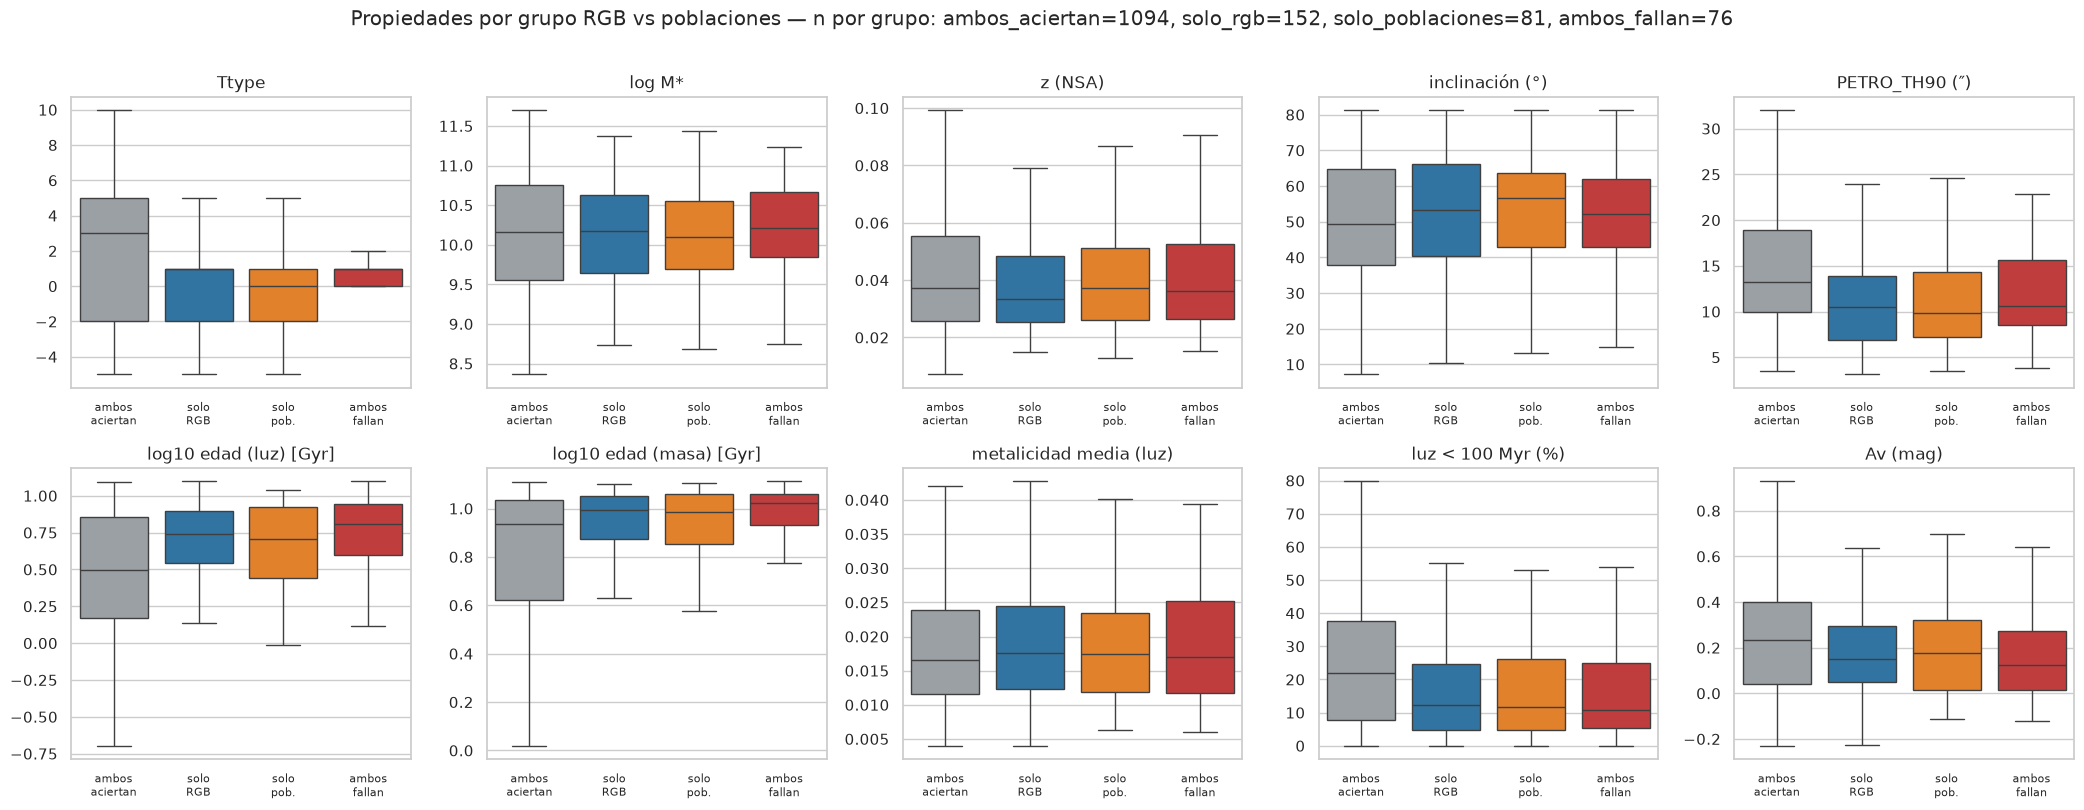

In [14]:
sl = pd.read_csv(STARLIGHT_INDEX)
assert sl.name.is_unique
SL_COLS = ["age_mean_light_gyr", "age_mean_mass_gyr", "z_mean_light", "light_young_lt_100myr_pct", "av_mag"]
P = D.merge(manifest[["name", "Type", "Ttype", "LogMass", "nsa_z", "incl", "PETRO_TH90", "fov_0_path"]], on="name", how="left", validate="one_to_one") \
     .merge(sl[["name"] + SL_COLS], on="name", how="left", validate="one_to_one")
P["log10_edad_luz"] = np.log10(P.age_mean_light_gyr)
P["log10_edad_masa"] = np.log10(P.age_mean_mass_gyr)
print(f"Galaxias en {EVAL_SPLIT}: {len(P)} | con Ttype: {int(P.Ttype.notna().sum())} | con propiedades STARLIGHT: {int(P.age_mean_light_gyr.notna().sum())}")
print("Etiqueta vs Ttype (verificación de la definición):", P.groupby("label").Ttype.agg(["min", "max"]).to_dict("index"))

PROPS = {"Ttype": "Ttype", "LogMass": "log M*", "nsa_z": "z (NSA)", "incl": "inclinación (°)", "PETRO_TH90": "PETRO_TH90 (″)",
         "log10_edad_luz": "log10 edad (luz) [Gyr]", "log10_edad_masa": "log10 edad (masa) [Gyr]",
         "z_mean_light": "metalicidad media (luz)", "light_young_lt_100myr_pct": "luz < 100 Myr (%)", "av_mag": "Av (mag)"}
tab = {}
for c, nm in PROPS.items():
    row = {}
    for g in GROUP_ORDER:
        v = P.loc[P.grupo_rgb_pob == g, c].dropna()
        row[g] = f"{v.median():.2f} [{v.quantile(.25):.2f}–{v.quantile(.75):.2f}] (n={len(v)})"
    groups_v = [P.loc[P.grupo_rgb_pob == g, c].dropna() for g in GROUP_ORDER]
    row["Kruskal p"] = stats.kruskal(*groups_v).pvalue
    a, b = P.loc[P.grupo_rgb_pob == "solo_poblaciones", c].dropna(), P.loc[P.grupo_rgb_pob == "ambos_fallan", c].dropna()
    row["MWU p (solo_pob vs ambos_fallan)"] = stats.mannwhitneyu(a, b).pvalue if len(a) and len(b) else np.nan
    tab[nm] = row
prop_table = pd.DataFrame(tab).T
prop_table["MWU p Bonferroni"] = (prop_table["MWU p (solo_pob vs ambos_fallan)"] * len(PROPS)).clip(upper=1)
display(prop_table.style.format({"Kruskal p": "{:.2g}", "MWU p (solo_pob vs ambos_fallan)": "{:.2g}", "MWU p Bonferroni": "{:.2g}"}))
save_table(prop_table.reset_index(names="propiedad"), "propiedades_por_grupo")

fig, axes = plt.subplots(2, 5, figsize=(21, 8))
for a, (c, nm) in zip(axes.ravel(), PROPS.items()):
    sns.boxplot(data=P, x="grupo_rgb_pob", y=c, order=GROUP_ORDER, hue="grupo_rgb_pob", palette=GROUP_COLORS, legend=False, showfliers=False, ax=a)
    a.set(title=nm, xlabel="", ylabel="")
    a.set_xticks(range(4), ["ambos\naciertan", "solo\nRGB", "solo\npob.", "ambos\nfallan"], fontsize=8)
plt.suptitle("Propiedades por grupo RGB vs poblaciones — n por grupo: " + ", ".join(f"{g}={int((P.grupo_rgb_pob == g).sum())}" for g in GROUP_ORDER), y=1.01)
plt.tight_layout()
save_fig(fig, "D_propiedades_por_grupo")
plt.show()

,tipo,etiqueta,n,err_rgb_resnet,err_pob,err_esp_fov,err_esp_sl,err_esp_sl_attn,n_err_rgb,rescate_pob_a_rgb,desacuerdo_rgb_pob,pct_solo_pob,pct_solo_rgb
Ttype,,,,,,,,,,,,,
-5,E,temprana,270,0.0296,0.1222,0.2370,0.2815,0.1111,8,0.3750,0.1148,0.0111,0.1037
-2,S0,temprana,177,0.2147,0.2429,0.3503,0.3785,0.2147,38,0.6842,0.3220,0.1469,0.1751
0,S0a,temprana,81,0.3457,0.3704,0.5185,0.6049,0.3827,28,0.5000,0.3704,0.1728,0.1975
1,,tardia,145,0.3241,0.5172,0.4414,0.4069,0.4966,47,0.3830,0.4414,0.1241,0.3172
2,,tardia,141,0.1702,0.1915,0.2766,0.2340,0.1986,24,0.5833,0.2199,0.0993,0.1206
3,,tardia,157,0.0446,0.1019,0.0701,0.0637,0.1210,7,0.2857,0.0828,0.0127,0.0701
4,,tardia,144,0.0069,0.0069,0.0208,0.0139,0.0069,1,1.0000,0.0139,0.0069,0.0069
5,,tardia,155,0.0065,0.0129,0.0000,0.0000,0.0129,1,1.0000,0.0194,0.0065,0.0129
6,,tardia,66,0.0152,0.0000,0.0303,0.0000,0.0000,1,1.0000,0.0152,0.0152,0.0000


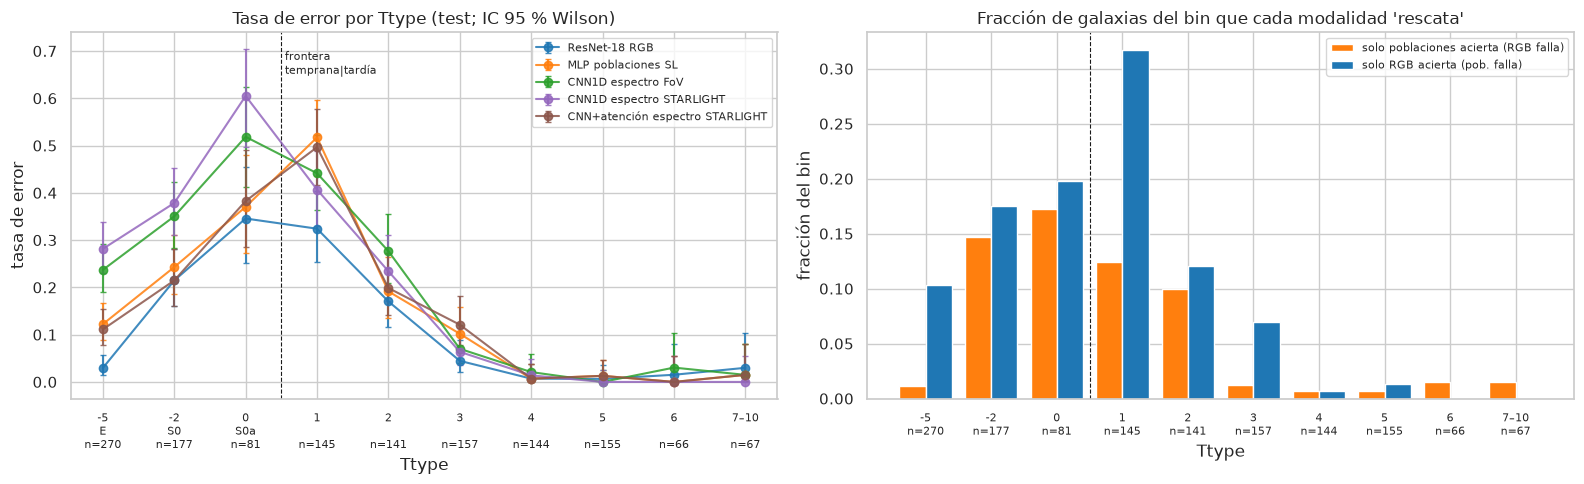

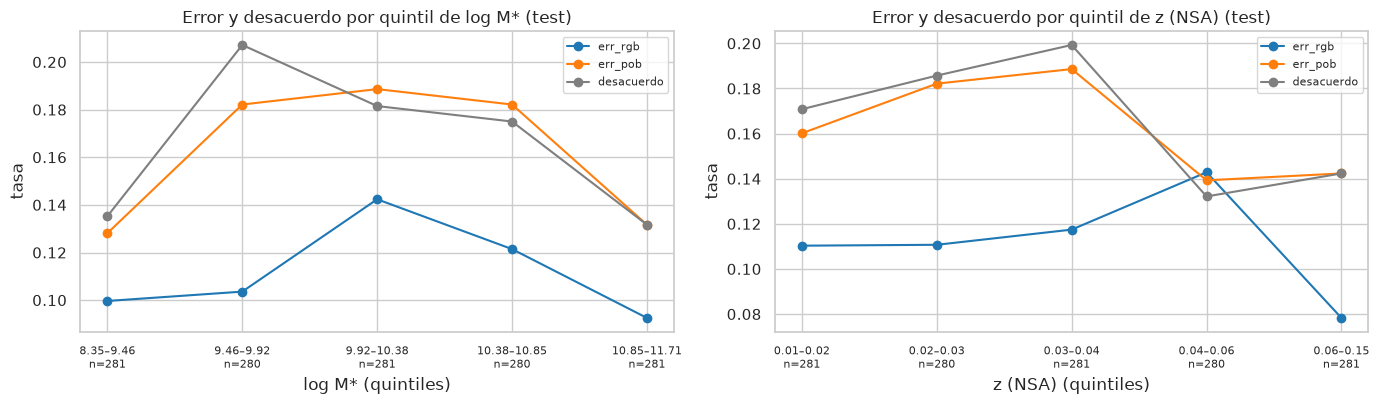

In [15]:
# Análisis por Ttype (agrupando 7–10 por tamaño de muestra)
def ttype_bin(t):
    return "7–10" if t >= 7 else str(int(t))


P["ttype_bin"] = P.Ttype.map(ttype_bin)
TT_ORDER = ["-5", "-2", "0", "1", "2", "3", "4", "5", "6", "7–10"]
TT_NAMES = {"-5": "E", "-2": "S0", "0": "S0a"}


def wilson(k, n, z=1.96):
    if n == 0:
        return (np.nan, np.nan)
    ph = k / n
    c = (ph + z * z / (2 * n)) / (1 + z * z / n)
    h = z * np.sqrt(ph * (1 - ph) / n + z * z / (4 * n * n)) / (1 + z * z / n)
    return c - h, c + h


rows = []
for t in TT_ORDER:
    s = P[P.ttype_bin == t]
    n = len(s)
    r = {"Ttype": t, "tipo": TT_NAMES.get(t, ""), "etiqueta": "temprana" if t in ("-5", "-2", "0") else "tardia", "n": n}
    for k in ["rgb_resnet", "pob", "esp_fov", "esp_sl", "esp_sl_attn"]:
        e = int((~s[f"ok_{k}"]).sum())
        lo, hi = wilson(e, n)
        r.update({f"err_{k}": e / n if n else np.nan, f"err_{k}_lo": lo, f"err_{k}_hi": hi})
    e_rgb = ~s[f"ok_{REF}"]
    r["n_err_rgb"] = int(e_rgb.sum())
    r["rescate_pob_a_rgb"] = (e_rgb & s.ok_pob).sum() / e_rgb.sum() if e_rgb.sum() else np.nan
    r["desacuerdo_rgb_pob"] = (s[f"pred_{REF}"] != s.pred_pob).mean()
    r["pct_solo_pob"] = (s.grupo_rgb_pob == "solo_poblaciones").mean()
    r["pct_solo_rgb"] = (s.grupo_rgb_pob == "solo_rgb").mean()
    rows.append(r)
tt = pd.DataFrame(rows)
display(tt.set_index("Ttype")[["tipo", "etiqueta", "n", "err_rgb_resnet", "err_pob", "err_esp_fov", "err_esp_sl", "err_esp_sl_attn", "n_err_rgb", "rescate_pob_a_rgb", "desacuerdo_rgb_pob", "pct_solo_pob", "pct_solo_rgb"]])
save_table(tt, "error_por_ttype")

fig, ax = plt.subplots(1, 2, figsize=(16, 5))
xs = np.arange(len(TT_ORDER))
for k, c in zip(["rgb_resnet", "pob", "esp_fov", "esp_sl", "esp_sl_attn"], ["tab:blue", "tab:orange", "tab:green", "tab:purple", "tab:brown"]):
    y = tt[f"err_{k}"].to_numpy()
    ax[0].errorbar(xs, y, yerr=[y - tt[f"err_{k}_lo"], tt[f"err_{k}_hi"] - y], marker="o", capsize=2, color=c, label=NAMES[k], alpha=0.85)
ax[0].axvline(2.5, color="k", ls="--", lw=0.8)
ax[0].text(2.55, ax[0].get_ylim()[1] * 0.95, "frontera\ntemprana|tardía", fontsize=8, va="top")
ax[0].set_xticks(xs, [f"{t}\n{TT_NAMES.get(t, '')}\nn={n}" for t, n in zip(tt.Ttype, tt.n)], fontsize=8)
ax[0].set(title=f"Tasa de error por Ttype ({EVAL_SPLIT}; IC 95 % Wilson)", ylabel="tasa de error", xlabel="Ttype")
ax[0].legend(fontsize=8)
ax[1].bar(xs - 0.2, tt.pct_solo_pob, 0.4, color="#ff7f0e", label="solo poblaciones acierta (RGB falla)")
ax[1].bar(xs + 0.2, tt.pct_solo_rgb, 0.4, color="#1f77b4", label="solo RGB acierta (pob. falla)")
ax[1].set_xticks(xs, [f"{t}\nn={n}" for t, n in zip(tt.Ttype, tt.n)], fontsize=8)
ax[1].set(title="Fracción de galaxias del bin que cada modalidad 'rescata'", ylabel="fracción del bin", xlabel="Ttype")
ax[1].axvline(2.5, color="k", ls="--", lw=0.8)
ax[1].legend(fontsize=8)
plt.tight_layout()
save_fig(fig, "D_error_por_ttype")
plt.show()

# Masa y redshift por quintiles
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
mz_rows = []
for a, (c, nm) in zip(ax, [("LogMass", "log M*"), ("nsa_z", "z (NSA)")]):
    P[f"{c}_q"] = pd.qcut(P[c], 5)
    g = P.groupby(f"{c}_q", observed=True)
    res = pd.DataFrame({"n": g.size(), "err_rgb": g.apply(lambda s: (~s[f"ok_{REF}"]).mean()), "err_pob": g.apply(lambda s: (~s.ok_pob).mean()),
                        "desacuerdo": g.apply(lambda s: (s[f"pred_{REF}"] != s.pred_pob).mean())})
    for col, color in [("err_rgb", "tab:blue"), ("err_pob", "tab:orange"), ("desacuerdo", "tab:gray")]:
        a.plot(range(5), res[col], marker="o", color=color, label=col)
    a.set_xticks(range(5), [f"{i.left:.2f}–{i.right:.2f}\nn={n}" for i, n in zip(res.index, res.n)], fontsize=8)
    a.set(title=f"Error y desacuerdo por quintil de {nm} ({EVAL_SPLIT})", ylabel="tasa", xlabel=f"{nm} (quintiles)")
    a.legend(fontsize=8)
    mz_rows.append(res.reset_index(names="bin").assign(variable=c, bin=lambda x: x["bin"].astype(str)))
plt.tight_layout()
save_fig(fig, "D_error_por_masa_z")
plt.show()
mz = pd.concat(mz_rows)

In [16]:
tt_ok = tt[tt.n >= 30]
hi = tt_ok.loc[tt_ok.desacuerdo_rgb_pob.idxmax()]
hr = tt_ok.loc[tt_ok.err_rgb_resnet.idxmax()]
hp = tt_ok.loc[tt_ok.err_pob.idxmax()]
near = tt[tt.Ttype.isin(["0", "1"])]
far = tt[~tt.Ttype.isin(["0", "1"])]
print(f"- Mayor error RGB: Ttype {hr.Ttype} ({hr.err_rgb_resnet:.1%}, n={hr.n}); mayor error poblaciones: Ttype {hp.Ttype} ({hp.err_pob:.1%}, n={hp.n}); "
      f"mayor desacuerdo RGB-pob.: Ttype {hi.Ttype} ({hi.desacuerdo_rgb_pob:.1%}, n={hi.n}) [solo bins con n≥30].")
e_near = (near.err_rgb_resnet * near.n).sum() / near.n.sum()
e_far = (far.err_rgb_resnet * far.n).sum() / far.n.sum()
print(f"- Error RGB en la frontera (Ttype 0–1, n={near.n.sum()}): {e_near:.1%} vs resto (n={far.n.sum()}): {e_far:.1%}. "
      f"Para poblaciones: {(near.err_pob * near.n).sum() / near.n.sum():.1%} vs {(far.err_pob * far.n).sum() / far.n.sum():.1%}.")
sh = int(near.n_err_rgb.sum())
print(f"- Fracción de los errores RGB que cae en Ttype 0–1: {sh / int((~P[f'ok_{REF}']).sum()):.1%} (la frontera contiene {near.n.sum() / len(P):.1%} de las galaxias).")
tt_s = tt.set_index("Ttype")
print(f"- Elípticas (Ttype −5, n={tt_s.loc['-5', 'n']}) vs S0 (−2, n={tt_s.loc['-2', 'n']}): error RGB {tt_s.loc['-5', 'err_rgb_resnet']:.1%} vs {tt_s.loc['-2', 'err_rgb_resnet']:.1%}; "
      f"error pob. {tt_s.loc['-5', 'err_pob']:.1%} vs {tt_s.loc['-2', 'err_pob']:.1%}.")
sig = prop_table[prop_table["MWU p Bonferroni"] < 0.05].index.tolist()
print(f"- Propiedades que distinguen 'solo poblaciones' de 'ambos fallan' (MWU, Bonferroni<0.05; n={int((P.grupo_rgb_pob == 'solo_poblaciones').sum())} vs {int((P.grupo_rgb_pob == 'ambos_fallan').sum())}): {sig or 'ninguna'}.")
print("  Asociación ≠ causalidad; con grupos de decenas de galaxias, conclusiones fuertes no están justificadas.")

- Mayor error RGB: Ttype 0 (34.6%, n=81); mayor error poblaciones: Ttype 1 (51.7%, n=145); mayor desacuerdo RGB-pob.: Ttype 1 (44.1%, n=145) [solo bins con n≥30].
- Error RGB en la frontera (Ttype 0–1, n=226): 33.2% vs resto (n=1177): 7.0%. Para poblaciones: 46.5% vs 10.5%.
- Fracción de los errores RGB que cae en Ttype 0–1: 47.8% (la frontera contiene 16.1% de las galaxias).
- Elípticas (Ttype −5, n=270) vs S0 (−2, n=177): error RGB 3.0% vs 21.5%; error pob. 12.2% vs 24.3%.
- Propiedades que distinguen 'solo poblaciones' de 'ambos fallan' (MWU, Bonferroni<0.05; n=81 vs 76): ninguna.
  Asociación ≠ causalidad; con grupos de decenas de galaxias, conclusiones fuertes no están justificadas.


## 7. Galería de galaxias discordantes

**Pregunta:** ¿qué patrones visuales aparecen en galaxias concretas donde los modelos discrepan?

Se muestran imágenes RGB (`fov_0` ya descargadas, rutas del manifest) de la tabla `galaxias_discordantes` (sección 5), ordenadas por el score documentado de cada grupo. Cada título incluye etiqueta verdadera, Ttype, probabilidades/predicciones, masa, z y propiedades STARLIGHT. No se descarga nada.

In [28]:
GALLERY_GROUPS = ["rgb_falla_pob_acierta", "rgb_acierta_pob_falla", "ambos_fallan", "contradictorias_confiadas", "cerca_frontera_rgb"]  # editable
N_GALLERY = 6    # galaxias por grupo (editable)
GALLERY_COLS = 3
sl_idx = sl.set_index("name")


def show_gallery(group, n=N_GALLERY, cols=GALLERY_COLS):
    sel = disc[disc.grupo == group].head(n)
    if sel.empty:
        print(f"Grupo vacío: {group}")
        return
    nr = int(np.ceil(len(sel) / cols))
    fig, axes = plt.subplots(nr, cols, figsize=(4.4 * cols, 4.9 * nr), squeeze=False)
    for a in axes.ravel():
        a.axis("off")
    for a, (_, r) in zip(axes.ravel(), sel.iterrows()):
        path = ROOT / r.fov_0_path if isinstance(r.fov_0_path, str) else None
        if path is not None and path.exists():
            a.imshow(plt.imread(path))
        else:
            a.text(0.5, 0.5, "imagen no disponible", ha="center")
        age = sl_idx.age_mean_light_gyr.get(r["name"], np.nan)
        young = sl_idx.light_young_lt_100myr_pct.get(r["name"], np.nan)
        a.set_title(f"{r['name']}\nreal={r.label} | Ttype={r.Ttype:.0f} ({r.Type})\n"
                    f"P(RGB)={r[f'p_{REF}']:.2f} → {r[f'pred_{REF}']} | P(pob)={r.p_pob:.2f} → {r.pred_pob}\n"
                    f"P(esp FoV)={r.p_esp_fov:.2f} | logM={r.LogMass:.2f} z={r.nsa_z:.3f}\n"
                    f"edad_luz={age:.1f} Gyr | joven={young:.0f}%", fontsize=7.5)
    plt.suptitle(f"{group} — n total en {EVAL_SPLIT}: {int(sel.n_grupo.iloc[0])} (mostradas {len(sel)})", y=1.0)
    plt.tight_layout()
    save_fig(fig, f"E_galeria_{group}")
    plt.show()


for g in GALLERY_GROUPS:
    show_gallery(g)

SyntaxError: incomplete input (406083207.py, line 35)

In [18]:
gd = disc.merge(sl[["name", "age_mean_light_gyr", "light_young_lt_100myr_pct", "av_mag"]], on="name", how="left")
for g in GALLERY_GROUPS:
    s = gd[gd.grupo == g]
    print(f"- {g}: n total={int(s.n_grupo.iloc[0])}; top-{len(s)} → % tardías={s.y_true.mean():.0%}, Ttype mediano={s.Ttype.median():.1f}, "
          f"logM mediana={s.LogMass.median():.2f}, edad luz mediana={s.age_mean_light_gyr.median():.1f} Gyr.")
print("- La galería es cualitativa: sirve para formular hipótesis (p. ej. morfologías peculiares, inclinación alta, compañeras), no para contrastarlas.")

- rgb_falla_pob_acierta: n total=81; top-30 → % tardías=60%, Ttype mediano=1.0, logM mediana=10.07, edad luz mediana=4.2 Gyr.
- rgb_acierta_pob_falla: n total=152; top-30 → % tardías=37%, Ttype mediano=-1.0, logM mediana=9.92, edad luz mediana=4.7 Gyr.
- ambos_fallan: n total=76; top-30 → % tardías=47%, Ttype mediano=0.0, logM mediana=10.19, edad luz mediana=5.9 Gyr.
- contradictorias_confiadas: n total=9; top-9 → % tardías=22%, Ttype mediano=-2.0, logM mediana=9.64, edad luz mediana=1.9 Gyr.
- cerca_frontera_rgb: n total=108; top-30 → % tardías=63%, Ttype mediano=1.0, logM mediana=9.88, edad luz mediana=5.0 Gyr.
- La galería es cualitativa: sirve para formular hipótesis (p. ej. morfologías peculiares, inclinación alta, compañeras), no para contrastarlas.


## 8. Fusión tardía de probabilidades (exploración solo en validation)

**Pregunta:** si hay complementariedad potencial, ¿se puede aprovechar con un mecanismo simple, sin reentrenar encoders?

`p_fusión = α · p_RGB + (1 − α) · p_otra`, con α ∈ [0, 1] (α = 1 es RGB sola; α = 0 es la otra modalidad; α = 0.5 es el promedio simple, usado como control).

**Protocolo (regla fijada antes de ver los resultados):**
1. Solo `validation` para explorar α (rejilla de paso 0.05).
2. Métricas: ROC-AUC, macro-F1 y balanced accuracy (umbral 0.5) y Brier.
3. **Regla de elección:** suavizar la curva de AUC con media móvil centrada de 3 puntos (α±0.05) y elegir el α con mayor AUC suavizado; se considera **región estable** el conjunto de α cuyo AUC suavizado está a ≤ 0.002 del máximo.
4. `test` **no** interviene en la elección: se muestra después como evaluación histórica con el α ya fijado.

Cuidado: los modelos pueden estar calibrados distinto y su checkpoint fue elegido con el AUC de `validation`, por lo que los AUC de validation son algo optimistas para cada modelo individual.

Galaxias en validation: 1403
('rgb_resnet', 'pob') {'alpha_star': np.float64(0.85), 'stable_min': np.float64(0.7), 'stable_max': np.float64(1.0), 'contiguous': True}
('rgb_resnet', 'esp_fov') {'alpha_star': np.float64(1.0), 'stable_min': np.float64(0.8), 'stable_max': np.float64(1.0), 'contiguous': True}
('rgb_resnet', 'esp_sl_attn') {'alpha_star': np.float64(0.85), 'stable_min': np.float64(0.65), 'stable_max': np.float64(1.0), 'contiguous': True}


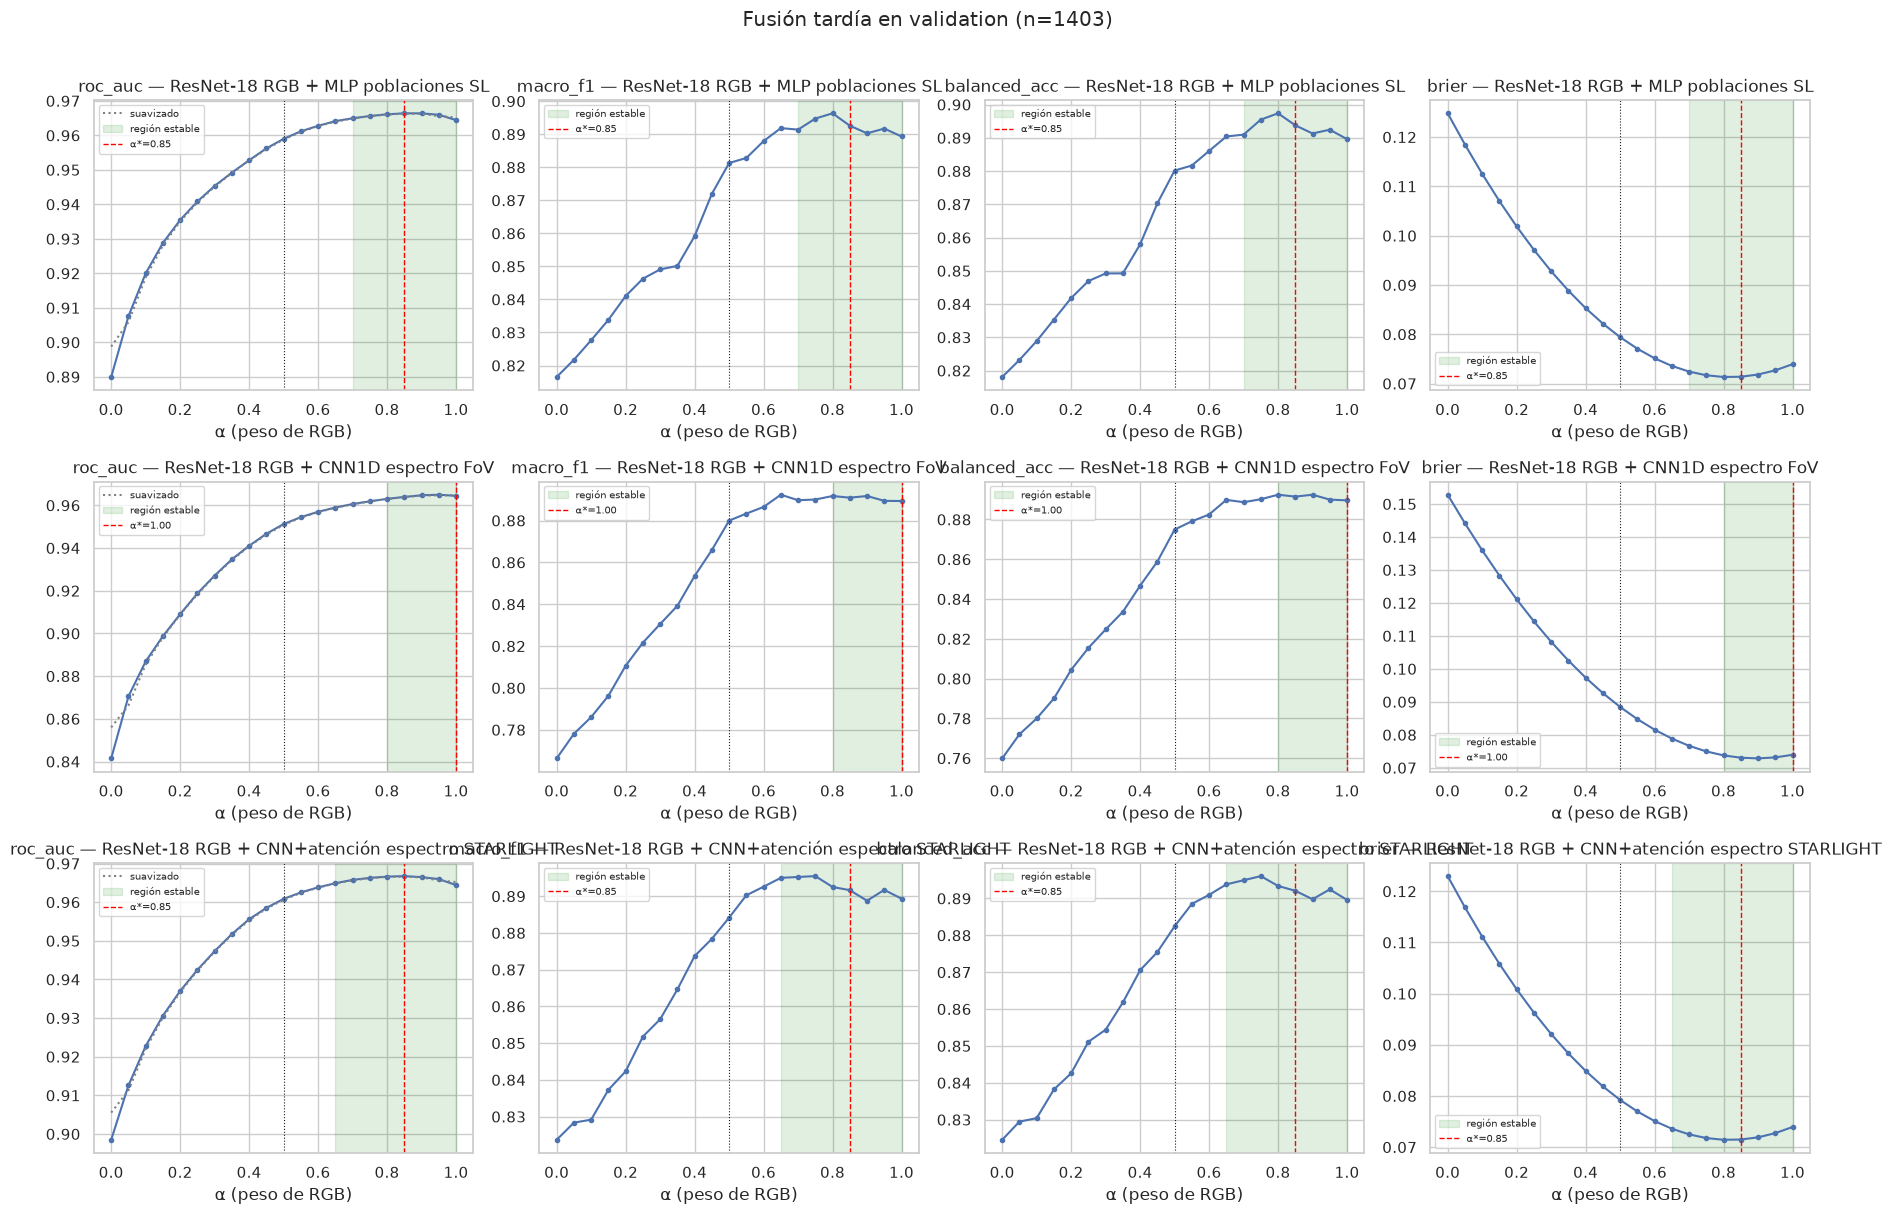

In [26]:
ALPHAS = np.round(np.linspace(0, 1, 21), 2)
FUSION_PAIRS = [("rgb_resnet", "pob"), ("rgb_resnet", "esp_fov"), ("rgb_resnet","esp_sl_attn")]  # la primera es la prioritaria
TOL = 0.002


def fusion_curve(d, a, b, alphas=ALPHAS):
    rows = []
    for al in alphas:
        p = al * d[f"p_{a}"] + (1 - al) * d[f"p_{b}"]
        pred = (p >= 0.5).astype(int)
        rows.append({"alpha": al, "roc_auc": roc_auc_score(d.y_true, p), "macro_f1": f1_score(d.y_true, pred, average="macro"),
                     "balanced_acc": balanced_accuracy_score(d.y_true, pred), "brier": brier_score_loss(d.y_true, p)})
    return pd.DataFrame(rows)


dval = split_df(SELECT_SPLIT)
fus, choice = {}, {}
for a, b in FUSION_PAIRS:
    c = fusion_curve(dval, a, b)
    c["auc_suavizado"] = c.roc_auc.rolling(3, center=True, min_periods=2).mean()
    best_i = c.auc_suavizado.idxmax()
    alpha_star = c.loc[best_i, "alpha"]
    stable = c[c.auc_suavizado >= c.auc_suavizado.max() - TOL].alpha
    contiguous = stable.diff().round(2).fillna(0.05).le(0.05).all()
    fus[(a, b)] = c
    choice[(a, b)] = {"alpha_star": alpha_star, "stable_min": stable.min(), "stable_max": stable.max(), "contiguous": bool(contiguous)}

fus_out = pd.concat([c.assign(par=f"{a}+{b}", split=SELECT_SPLIT, n=len(dval)) for (a, b), c in fus.items()])
save_table(fus_out, "resultados_fusion_validation")
print(f"Galaxias en {SELECT_SPLIT}: {len(dval)}")
for kp, ch in choice.items():
    print(kp, ch)

fig, axes = plt.subplots(len(FUSION_PAIRS), 4, figsize=(18, 4 * len(FUSION_PAIRS)), squeeze=False)
for row, (a, b) in zip(axes, FUSION_PAIRS):
    c, ch = fus[(a, b)], choice[(a, b)]
    for ax_, m in zip(row, ["roc_auc", "macro_f1", "balanced_acc", "brier"]):
        ax_.plot(c.alpha, c[m], marker="o", ms=3)
        if m == "roc_auc":
            ax_.plot(c.alpha, c.auc_suavizado, color="gray", ls=":", label="suavizado")
        ax_.axvspan(ch["stable_min"], ch["stable_max"], color="green", alpha=0.12, label="región estable")
        ax_.axvline(ch["alpha_star"], color="red", ls="--", lw=1, label=f"α*={ch['alpha_star']:.2f}")
        ax_.axvline(0.5, color="k", ls=":", lw=0.8)
        ax_.set(title=f"{m} — {NAMES[a]} + {NAMES[b]}", xlabel="α (peso de RGB)")
        ax_.legend(fontsize=7)
plt.suptitle(f"Fusión tardía en {SELECT_SPLIT} (n={len(dval)})", y=1.01)
plt.tight_layout()
save_fig(fig, "F_fusion_validation")
plt.show()

In [27]:
# Comparación sobre los mismos objetos: validation (exploración) y test (evaluación histórica con α* ya fijado)
rows = []
for (a, b), ch in choice.items():
    for s in [SELECT_SPLIT, EVAL_SPLIT]:
        d = split_df(s)
        for nm, al in [("RGB sola (α=1)", 1.0), ("otra modalidad (α=0)", 0.0), ("promedio simple (α=0.5)", 0.5), (f"fusión α*={ch['alpha_star']:.2f}", ch["alpha_star"])]:
            c = fusion_curve(d, a, b, [al]).iloc[0]
            rows.append({"par": f"{a}+{b}", "split": s, "n": len(d), "config": nm, **c.drop("alpha").to_dict()})
fus_cmp = pd.DataFrame(rows)
display(fus_cmp.set_index(["par", "split", "config"]))
save_table(fus_cmp, "fusion_comparacion_val_test")

# Referencia: fusión entrenada (concat) ya existente
for k in ["rgb_pob", "rgb_esp_fov"]:
    m = metrics_all[(metrics_all.modelo == k)].set_index("split")
    print(f"{NAMES[k]} (concat entrenada) — AUC val {m.loc['validation', 'roc_auc']:.4f}, test {m.loc['test', 'roc_auc']:.4f}")

n  roc_auc  macro_f1  balanced_acc  brier
par                    split      config                                                               
rgb_resnet+pob         validation RGB sola (α=1)           1403   0.9644    0.8893        0.8896 0.0739
                                  otra modalidad (α=0)     1403   0.8899    0.8165        0.8181 0.1248
                                  promedio simple (α=0.5)  1403   0.9590    0.8813        0.8802 0.0794
                                  fusión α*=0.85           1403   0.9664    0.8926        0.8938 0.0714
                       test       RGB sola (α=1)           1403   0.9633    0.8812        0.8825 0.0772
                                  otra modalidad (α=0)     1403   0.8949    0.8279        0.8299 0.1216
                                  promedio simple (α=0.5)  1403   0.9581    0.8856        0.8863 0.0802
                                  fusión α*=0.85           1403   0.9637    0.8826        0.8836 0.0740
rgb_resnet+esp_fov     validation RGB sola (α=1)           1403   0.9644    0.8893        0.8896 0.0739
                                  otra modalidad (α=0)     1403   0.8415    0.7663        0.7599 0.1528
                                  promedio simple (α=0.5)  1403   0.9512    0.8800        0.8749 0.0884
                                  fusión α*=1.00           1403   0.9644    0.8893        0.8896 0.0739
                       test       RGB sola (α=1)           1403   0.9633    0.8812        0.8825 0.0772
                                  otra modalidad (α=0)     1403   0.8572    0.7771        0.7723 0.1474
                                  promedio simple (α=0.5)  1403   0.9519    0.8848        0.8829 0.0878
                                  fusión α*=1.00           1403   0.9633    0.8812        0.8825 0.0772
rgb_resnet+esp_sl_attn validation RGB sola (α=1)           1403   0.9644    0.8893        0.8896 0.0739
                                  otra modalidad (α=0)     1403   0.8985    0.8237        0.8245 0.1230
                                  promedio simple (α=0.5)  1403   0.9609    0.8842        0.8824 0.0792
                                  fusión α*=0.85           1403   0.9667    0.8916        0.8921 0.0715
                       test       RGB sola (α=1)           1403   0.9633    0.8812        0.8825 0.0772
                                  otra modalidad (α=0)     1403   0.9066    0.8329        0.8360 0.1171
                                  promedio simple (α=0.5)  1403   0.9607    0.8877        0.8880 0.0790
                                  fusión α*=0.85           1403   0.9644    0.8841        0.8848 0.0739

RGB + poblaciones (concat entrenada) — AUC val 0.9629, test 0.9639
RGB + espectro FoV (concat entrenada) — AUC val 0.9643, test 0.9635


In [21]:
for (a, b), ch in choice.items():
    f = fus_cmp[(fus_cmp.par == f"{a}+{b}") & (fus_cmp.split == SELECT_SPLIT)].set_index("config")
    rg, fu, av = f.loc["RGB sola (α=1)"], f.iloc[3], f.loc["promedio simple (α=0.5)"]
    ft = fus_cmp[(fus_cmp.par == f"{a}+{b}") & (fus_cmp.split == EVAL_SPLIT)].set_index("config")
    print(f"- {NAMES[a]} + {NAMES[b]}: α*={ch['alpha_star']:.2f}; región estable α∈[{ch['stable_min']:.2f}, {ch['stable_max']:.2f}] (contigua: {ch['contiguous']}).")
    print(f"  validation: AUC RGB {rg.roc_auc:.4f} → fusión {fu.roc_auc:.4f} (Δ={fu.roc_auc - rg.roc_auc:+.4f}); α=0.5: {av.roc_auc:.4f}. "
          f"Brier {rg.brier:.4f} → {fu.brier:.4f}; bal.acc {rg.balanced_acc:.4f} → {fu.balanced_acc:.4f}.")
    print(f"  test (histórico, α fijado en validation): AUC {ft.iloc[0].roc_auc:.4f} → {ft.iloc[3].roc_auc:.4f} (Δ={ft.iloc[3].roc_auc - ft.iloc[0].roc_auc:+.4f}).")

- ResNet-18 RGB + MLP poblaciones SL: α*=0.85; región estable α∈[0.70, 1.00] (contigua: True).
  validation: AUC RGB 0.9644 → fusión 0.9664 (Δ=+0.0020); α=0.5: 0.9590. Brier 0.0739 → 0.0714; bal.acc 0.8896 → 0.8938.
  test (histórico, α fijado en validation): AUC 0.9633 → 0.9637 (Δ=+0.0005).
- ResNet-18 RGB + CNN1D espectro FoV: α*=1.00; región estable α∈[0.80, 1.00] (contigua: True).
  validation: AUC RGB 0.9644 → fusión 0.9644 (Δ=+0.0000); α=0.5: 0.9512. Brier 0.0739 → 0.0739; bal.acc 0.8896 → 0.8896.
  test (histórico, α fijado en validation): AUC 0.9633 → 0.9633 (Δ=+0.0000).


## 9. Incertidumbre estadística (bootstrap pareado)

**Pregunta:** ¿las diferencias observadas son más grandes que el ruido de muestreo?

**Bootstrap pareado y estratificado por clase:** se remuestrean *galaxias* con reemplazo, separando tempranas y tardías (así nunca hay una sola clase), y **los mismos índices se aplican a todos los modelos**, preservando el emparejamiento. Cada estadístico se recalcula en cada remuestreo; los percentiles 2.5–97.5 dan el intervalo.

**Qué NO hace:** cuantifica la incertidumbre por *el conjunto de galaxias evaluadas* con predicciones fijas. No sustituye repetir el entrenamiento con distintas semillas ni mide la variabilidad del entrenamiento (que suele ser mayor).

**McNemar exacto:** contrasta, sobre las discordancias (solo A acierta = b, solo B acierta = c), la hipótesis de que ambos tienen la misma tasa de error (b ≈ c). No prueba que un modelo sea mejor en general ni informa del tamaño del efecto.

In [22]:
def strat_indices(y, B, seed):
    r = np.random.default_rng(seed)
    i0, i1 = np.where(y == 0)[0], np.where(y == 1)[0]
    return np.array([np.concatenate([r.choice(i0, len(i0)), r.choice(i1, len(i1))]) for _ in range(B)])


def boot(stat, idx):
    full = stat(np.arange(idx.shape[1]))
    vals = np.array([stat(ix) for ix in idx])
    vals = vals[~np.isnan(vals)]
    return full, np.percentile(vals, 2.5), np.percentile(vals, 97.5)


def run_bootstrap(d, split, pairs_auc, rescues, tag=""):
    y = d.y_true.to_numpy()
    idx = strat_indices(y, N_BOOT, SEED)
    out = []
    P_ = {c[2:]: d[c].to_numpy() for c in d if c.startswith("p_")}
    pred = {k[5:]: d[k].to_numpy() for k in d if k.startswith("pred_")}
    ok = {k[3:]: d[k].to_numpy().astype(bool) for k in d if k.startswith("ok_")}
    auc = lambda k: (lambda ix: roc_auc_score(y[ix], P_[k][ix]))
    bal = lambda k: (lambda ix: balanced_accuracy_score(y[ix], pred[k][ix]))
    for a, b, desc in pairs_auc:
        for metric, f in [("ΔAUC", auc), ("Δbalanced_acc", bal)]:
            fa, fb = f(a), f(b)
            est, lo, hi = boot(lambda ix: fa(ix) - fb(ix), idx)
            out.append({"comparacion": desc, "metrica": metric, "split": split, "estimacion": est, "ic95_inf": lo, "ic95_sup": hi, "n": len(d), "B": N_BOOT,
                        "excluye_0": bool(lo > 0 or hi < 0)})
    for a, b, desc in rescues:   # rescate de errores de a por b
        est, lo, hi = boot(lambda ix: (~ok[a][ix] & ok[b][ix]).sum() / max((~ok[a][ix]).sum(), 1), idx)
        out.append({"comparacion": desc, "metrica": "tasa_rescate", "split": split, "estimacion": est, "ic95_inf": lo, "ic95_sup": hi, "n": len(d), "B": N_BOOT, "excluye_0": bool(lo > 0)})
        est, lo, hi = boot(lambda ix: (ok[a][ix] | ok[b][ix]).mean() - ok[a][ix].mean(), idx)
        out.append({"comparacion": desc.replace("rescate", "ganancia oráculo"), "metrica": "ganancia_oraculo_acc", "split": split, "estimacion": est, "ic95_inf": lo, "ic95_sup": hi, "n": len(d), "B": N_BOOT, "excluye_0": bool(lo > 0)})
    return pd.DataFrame(out)


def mcnemar(d, a, b):
    oa, ob = d[f"ok_{a}"].to_numpy(), d[f"ok_{b}"].to_numpy()
    n_a, n_b = int((oa & ~ob).sum()), int((~oa & ob).sum())
    p = stats.binomtest(n_a, n_a + n_b, 0.5).pvalue if n_a + n_b else 1.0
    return {"A": a, "B": b, "solo_A_acierta": n_a, "solo_B_acierta": n_b, "p_mcnemar_exacto": p}


# α* de la fusión prioritaria, fijado en validation
a_f, b_f = FUSION_PAIRS[0]
alpha_star = choice[(a_f, b_f)]["alpha_star"]
splits_df = {}
for s in [SELECT_SPLIT, EVAL_SPLIT]:
    d = split_df(s).copy()
    d["p_late"] = alpha_star * d[f"p_{a_f}"] + (1 - alpha_star) * d[f"p_{b_f}"]
    d["pred_late"] = (d.p_late >= 0.5).astype(int)
    d["ok_late"] = d.pred_late == d.y_true
    splits_df[s] = d

cmp_auc = [("rgb_cnn", REF, "CNN RGB − ResNet RGB"), ("pob", "esp_sl", "Poblaciones − espectro SL"), ("esp_sl", "esp_fov", "Espectro SL − espectro FoV"),
           (REF, "pob", "ResNet RGB − poblaciones"),
           ("late", REF, f"Fusión tardía (α*={alpha_star:.2f}) − RGB"), ("rgb_pob", REF, "RGB+pob (concat) − RGB"),
           ("rgb_esp_fov", REF, "RGB+esp FoV (concat) − RGB"), ("rgb_esp_sl_pob", REF, "RGB+esp SL+pob (concat) − RGB"),
           ("esp_sl_attn", "esp_sl", "Espectro SL CNN+atención − CNN1D"), (REF, "esp_sl_attn", "ResNet RGB − espectro SL CNN+atención")]
cmp_resc = [(REF, "pob", "rescate poblaciones→RGB"), (REF, "esp_fov", "rescate espectro FoV→RGB"),
            (REF, "esp_sl", "rescate espectro SL→RGB"), (REF, "esp_sl_attn", "rescate espectro SL CNN+atención→RGB"), (REF, "rgb_cnn", "rescate CNN RGB→ResNet RGB")]

ci_test = run_bootstrap(splits_df[EVAL_SPLIT], EVAL_SPLIT, cmp_auc, cmp_resc)
ci_val = run_bootstrap(splits_df[SELECT_SPLIT], SELECT_SPLIT, [cmp_auc[4]], [])
ci = pd.concat([ci_test, ci_val], ignore_index=True)
ci["nota"] = np.where(ci.split == SELECT_SPLIT, "α* elegido en esta misma muestra: optimista", "")
save_table(ci, "intervalos_confianza")
display(ci.set_index(["split", "comparacion", "metrica"])[["estimacion", "ic95_inf", "ic95_sup", "excluye_0", "n"]])

mc = pd.DataFrame([mcnemar(splits_df[EVAL_SPLIT], a, b) for a, b in [(REF, "rgb_cnn"), (REF, "pob"), (REF, "rgb_pob"), (REF, "rgb_esp_fov"), (REF, "rgb_esp_sl_pob"), (REF, "late")]])
print(f"McNemar exacto ({EVAL_SPLIT}; sin corrección por comparaciones múltiples)")
display(mc)
save_table(mc, "mcnemar")

estimacion  ic95_inf  ic95_sup  excluye_0     n
split      comparacion                                   metrica                                                              
test       CNN RGB − ResNet RGB                          ΔAUC                     -0.0009   -0.0068    0.0043      False  1403
                                                         Δbalanced_acc             0.0167    0.0028    0.0302       True  1403
           Poblaciones − espectro SL                     ΔAUC                      0.0308    0.0192    0.0421       True  1403
                                                         Δbalanced_acc             0.0712    0.0503    0.0905       True  1403
           Espectro SL − espectro FoV                    ΔAUC                      0.0070    0.0019    0.0128       True  1403
                                                         Δbalanced_acc            -0.0136   -0.0254   -0.0020       True  1403
           ResNet RGB − poblaciones                      ΔAUC                      0.0683    0.0540    0.0836       True  1403
                                                         Δbalanced_acc             0.0526    0.0321    0.0759       True  1403
           Fusión tardía (α*=0.85) − RGB                 ΔAUC                      0.0005   -0.0012    0.0022      False  1403
                                                         Δbalanced_acc             0.0011   -0.0051    0.0072      False  1403
           RGB+pob (concat) − RGB                        ΔAUC                      0.0007   -0.0049    0.0059      False  1403
                                                         Δbalanced_acc             0.0104   -0.0040    0.0228      False  1403
           RGB+esp FoV (concat) − RGB                    ΔAUC                      0.0002   -0.0052    0.0050      False  1403
                                                         Δbalanced_acc            -0.0051   -0.0193    0.0080      False  1403
           RGB+esp SL+pob (concat) − RGB                 ΔAUC                      0.0017   -0.0027    0.0061      False  1403
                                                         Δbalanced_acc             0.0056   -0.0080    0.0180      False  1403
           Espectro SL CNN+atención − CNN1D              ΔAUC                      0.0425    0.0303    0.0545       True  1403
                                                         Δbalanced_acc             0.0772    0.0567    0.0966       True  1403
           ResNet RGB − espectro SL CNN+atención         ΔAUC                      0.0566    0.0433    0.0718       True  1403
                                                         Δbalanced_acc             0.0465    0.0255    0.0692       True  1403
           rescate poblaciones→RGB                       tasa_rescate              0.5159    0.4375    0.5875       True  1403
           ganancia oráculo poblaciones→RGB              ganancia_oraculo_acc      0.0577    0.0456    0.0684       True  1403
           rescate espectro FoV→RGB                      tasa_rescate              0.5096    0.4362    0.5890       True  1403
           ganancia oráculo espectro FoV→RGB             ganancia_oraculo_acc      0.0570    0.0463    0.0691       True  1403
           rescate espectro SL→RGB                       tasa_rescate              0.5159    0.4412    0.6026       True  1403
           ganancia oráculo espectro SL→RGB              ganancia_oraculo_acc      0.0577    0.0463    0.0699       True  1403
           rescate espectro SL CNN+atención→RGB          tasa_rescate              0.4968    0.4197    0.5769       True  1403
           ganancia oráculo espectro SL CNN+atención→RGB ganancia_oraculo_acc      0.0556    0.0435    0.0670       True  1403
           rescate CNN RGB→ResNet RGB                    tasa_rescate              0.3503    0.2746    0.4247       True  1403
           ganancia oráculo CNN RGB→ResNet RGB           ganancia_oraculo_acc      0.0392    0.0292    0.0492       True  1403
validation Fusi

McNemar exacto (test; sin corrección por comparaciones múltiples)


,A,B,solo_A_acierta,solo_B_acierta,p_mcnemar_exacto
0,rgb_resnet,rgb_cnn,37,55,0.0758
1,rgb_resnet,pob,152,81,0.0000
2,rgb_resnet,rgb_pob,37,52,0.1374
3,rgb_resnet,rgb_esp_fov,43,42,1.0000
4,rgb_resnet,rgb_esp_sl_pob,46,48,0.9179
5,rgb_resnet,late,6,8,0.7905


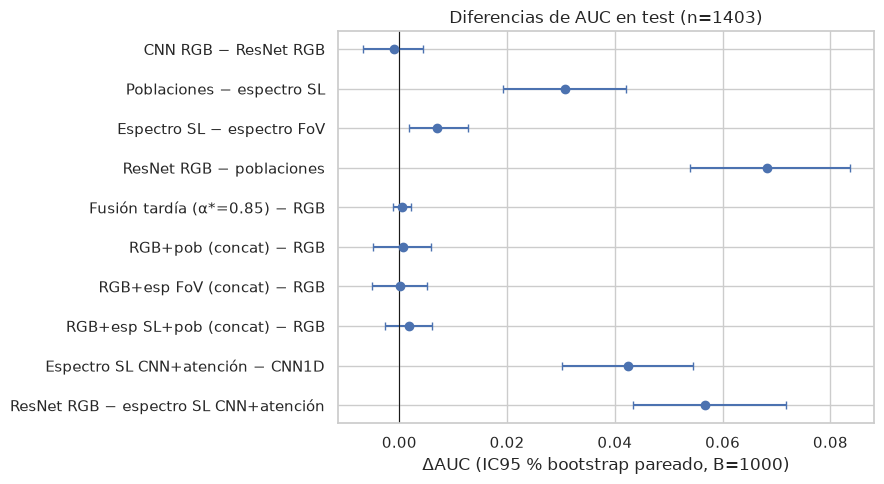

- Diferencias cuyo IC95 % excluye 0 (ΔAUC, test): Poblaciones − espectro SL, Espectro SL − espectro FoV, ResNet RGB − poblaciones, Espectro SL CNN+atención − CNN1D, ResNet RGB − espectro SL CNN+atención.
- Diferencias cuyo IC95 % NO excluye 0: CNN RGB − ResNet RGB, Fusión tardía (α*=0.85) − RGB, RGB+pob (concat) − RGB, RGB+esp FoV (concat) − RGB, RGB+esp SL+pob (concat) − RGB.
- Ganancia de la fusión tardía sobre RGB (test, histórica): ΔAUC=+0.0005 [-0.0012, +0.0022]; en validation (optimista): +0.0020 [-0.0004, +0.0042].
- Rescate de errores RGB por poblaciones: 51.6% [43.7%, 58.8%].
- Ganancia de accuracy del oráculo RGB∪pob.: +0.058 [+0.046, +0.068] (límite retrospectivo).
- Recordatorio: estos IC reflejan solo el muestreo de galaxias de test, no la variabilidad de entrenamiento (una sola semilla).


In [23]:
fig, ax = plt.subplots(figsize=(9, 5))
s = ci_test[ci_test.metrica == "ΔAUC"].reset_index(drop=True)
ax.errorbar(s.estimacion, range(len(s)), xerr=[s.estimacion - s.ic95_inf, s.ic95_sup - s.estimacion], fmt="o", capsize=3)
ax.axvline(0, color="k", lw=0.8)
ax.set_yticks(range(len(s)), s.comparacion)
ax.invert_yaxis()
ax.set(xlabel=f"ΔAUC (IC95 % bootstrap pareado, B={N_BOOT})", title=f"Diferencias de AUC en {EVAL_SPLIT} (n={len(splits_df[EVAL_SPLIT])})")
plt.tight_layout()
save_fig(fig, "G_delta_auc_bootstrap")
plt.show()

g = lambda c, m, sp=EVAL_SPLIT: ci[(ci.comparacion == c) & (ci.metrica == m) & (ci.split == sp)].iloc[0]
late_c = cmp_auc[4][2]
print("- Diferencias cuyo IC95 % excluye 0 (ΔAUC, test): " + ", ".join(s[s.excluye_0].comparacion) + ".")
print("- Diferencias cuyo IC95 % NO excluye 0: " + ", ".join(s[~s.excluye_0].comparacion) + ".")
r = g(late_c, "ΔAUC")
print(f"- Ganancia de la fusión tardía sobre RGB (test, histórica): ΔAUC={r.estimacion:+.4f} [{r.ic95_inf:+.4f}, {r.ic95_sup:+.4f}]; en validation (optimista): "
      f"{g(late_c, 'ΔAUC', SELECT_SPLIT).estimacion:+.4f} [{g(late_c, 'ΔAUC', SELECT_SPLIT).ic95_inf:+.4f}, {g(late_c, 'ΔAUC', SELECT_SPLIT).ic95_sup:+.4f}].")
r = g("rescate poblaciones→RGB", "tasa_rescate")
print(f"- Rescate de errores RGB por poblaciones: {r.estimacion:.1%} [{r.ic95_inf:.1%}, {r.ic95_sup:.1%}].")
r = g("rescate poblaciones→RGB".replace("rescate", "ganancia oráculo"), "ganancia_oraculo_acc")
print(f"- Ganancia de accuracy del oráculo RGB∪pob.: {r.estimacion:+.3f} [{r.ic95_inf:+.3f}, {r.ic95_sup:+.3f}] (límite retrospectivo).")
print("- Recordatorio: estos IC reflejan solo el muestreo de galaxias de test, no la variabilidad de entrenamiento (una sola semilla).")

## 10. Síntesis de hallazgos y próximos experimentos

Todo el texto siguiente se genera a partir de los resultados calculados arriba. Las reglas de decisión para el escenario son heurísticas documentadas (umbrales editables), no resultados estadísticos.

In [24]:
HIGH_SHARED = 0.70   # ≥70 % de los errores RGB son compartidos con la modalidad → errores "redundantes"
ORACLE_GAP = 0.04    # ganancia de oráculo ≥ 4 puntos de accuracy → complementariedad potencial "alta"

r_ref = pairs[(pairs.split == EVAL_SPLIT) & (pairs.A == REF) & pairs.B.isin(others)].set_index("B")
top = r_ref.rescate_B_a_A.idxmax()
rp = r_ref.loc["pob"]
late = g(late_c, "ΔAUC")
late_val = g(late_c, "ΔAUC", SELECT_SPLIT)
fusion_helps = (late.ic95_inf > 0) and (late_val.estimacion > 0)
oracle_gap = rp.ganancia_oraculo_vs_mejor
shared = rp.pct_errores_A_compartidos
if fusion_helps:
    scenario = "A — complementariedad real y fusión tardía favorable"
    rec = "validar con varias semillas y explorar fusiones más elaboradas (stacking, gating) con protocolo de validación cruzada."
elif oracle_gap >= ORACLE_GAP and shared < HIGH_SHARED:
    scenario = "B — alta cobertura del oráculo pero fusión tardía sin mejora demostrable"
    rec = "investigar *cuándo* confiar en cada modalidad: gated fusion, fusión basada en incertidumbre/calibración, stacking entrenado con validación cruzada."
else:
    scenario = "C — errores mayoritariamente redundantes (o ganancia potencial pequeña)"
    rec = "priorizar mejorar la representación espectral/regularización visual y estudiar físicamente los errores comunes antes de invertir en nuevas arquitecturas multimodales."

sig_props = ", ".join(sig) if sig else "ninguna propiedad con significancia tras Bonferroni"
lines = f"""
### Hallazgos observados (test, n={len(dte)}; descriptivos)

1. **Modalidad que más corrige a {NAMES[REF]}:** {NAMES[top]} (rescata {r_ref.loc[top, 'rescate_B_a_A']:.1%} de sus {int(r_ref.loc[top, 'errores_A'])} errores). Resto: {', '.join(f'{NAMES[k]} {v:.1%}' for k, v in r_ref.rescate_B_a_A.items() if k != top)}.
2. **Rescate potencial:** al menos una de las {len(others)} modalidades no-RGB acierta en {any_resc:.1%} de los errores RGB. IC95 % del rescate por poblaciones: [{g('rescate poblaciones→RGB', 'tasa_rescate').ic95_inf:.1%}, {g('rescate poblaciones→RGB', 'tasa_rescate').ic95_sup:.1%}].
3. **Errores compartidos vs complementarios (RGB–poblaciones):** {int(rp.ambos_fallan)} errores compartidos = {shared:.1%} de los errores RGB; Jaccard = {rp.jaccard_errores:.2f}. Oráculo = {rp.oraculo_acc:.3f} frente a {rp.acc_A:.3f} de RGB sola (+{oracle_gap:.3f}; retrospectivo).
4. **Ttype / masa / z:** mayor desacuerdo RGB–poblaciones en Ttype {hi.Ttype} ({hi.desacuerdo_rgb_pob:.1%}, n={hi.n}); error RGB en la frontera (Ttype 0–1) {e_near:.1%} vs {e_far:.1%} fuera de ella.
5. **Propiedades físicas asociadas a los objetos rescatados por poblaciones** (frente a los que ambos fallan): {sig_props}.
6. **Fusión tardía (α*={alpha_star:.2f}, elegido en validation; región estable [{choice[(a_f, b_f)]['stable_min']:.2f}, {choice[(a_f, b_f)]['stable_max']:.2f}]):** ΔAUC validation = {late_val.estimacion:+.4f}; test histórico = {late.estimacion:+.4f} [{late.ic95_inf:+.4f}, {late.ic95_sup:+.4f}]. Mejora consistente demostrada: **{'sí' if fusion_helps else 'no'}**.
7. **Robustez:** diferencias de AUC con IC95 % que excluye 0: {', '.join(ci_test[(ci_test.metrica == 'ΔAUC') & ci_test.excluye_0].comparacion) or 'ninguna'}.

### Escenario sugerido por las reglas: **{scenario}**
Recomendación condicionada: {rec}

### Hipótesis plausibles (no probadas aquí)
- Las poblaciones podrían aportar contexto físico (edad/masa/color) útil cuando la morfología visual es ambigua (p. ej. cerca de la frontera Ttype 0–1, punto 4); no se ha contrastado causalmente.
- El desacuerdo entre modalidades puede deberse tanto a información distinta como a ruido de entrenamiento: sin varias semillas no se pueden separar.

### Limitaciones metodológicas
- Una semilla y un solo split; los IC bootstrap no incluyen variabilidad de entrenamiento.
- `test` ya fue inspeccionado en el desarrollo: es descriptivo y no confirmatorio. El α* se eligió solo con validation, pero los checkpoints base se eligieron también con validation (AUC de validation optimista).
- STARLIGHT deriva del espectro: no es una modalidad independiente. Asociaciones físicas ≠ causalidad. Los subgrupos pequeños (p. ej. elípticas, Ttype ≥ 7) tienen IC amplios.
- Se comparó con una RGB de referencia ({NAMES[REF]}); la CNN compacta difiere sobre todo en punto de operación.

### Próximos pasos recomendados
- Repetir las configuraciones clave con 3–5 semillas (y/o validación cruzada) para separar efecto real de ruido de entrenamiento.
- Reservar un conjunto verdaderamente no visto (o validación cruzada anidada) para una evaluación confirmatoria de cualquier fusión.
- Calibrar las probabilidades por modalidad en datos independientes antes de fusionar, y probar stacking/gating entrenados con validación cruzada.
- Inspeccionar la galería de `ambos_fallan` y `cerca_frontera_rgb` para decidir si hay ruido de etiqueta en la frontera Ttype 0–1.
"""
display(Markdown(lines))


### Hallazgos observados (test, n=1403; descriptivos)

1. **Modalidad que más corrige a ResNet-18 RGB:** MLP poblaciones SL (rescata 51.6% de sus 157 errores). Resto: CNN1D espectro FoV 51.0%, CNN1D espectro STARLIGHT 51.6%, CNN+atención espectro STARLIGHT 49.7%.
2. **Rescate potencial:** al menos una de las 4 modalidades no-RGB acierta en 64.3% de los errores RGB. IC95 % del rescate por poblaciones: [43.7%, 58.8%].
3. **Errores compartidos vs complementarios (RGB–poblaciones):** 76 errores compartidos = 48.4% de los errores RGB; Jaccard = 0.25. Oráculo = 0.946 frente a 0.888 de RGB sola (+0.058; retrospectivo).
4. **Ttype / masa / z:** mayor desacuerdo RGB–poblaciones en Ttype 1 (44.1%, n=145); error RGB en la frontera (Ttype 0–1) 33.2% vs 7.0% fuera de ella.
5. **Propiedades físicas asociadas a los objetos rescatados por poblaciones** (frente a los que ambos fallan): ninguna propiedad con significancia tras Bonferroni.
6. **Fusión tardía (α*=0.85, elegido en validation; región estable [0.70, 1.00]):** ΔAUC validation = +0.0020; test histórico = +0.0005 [-0.0012, +0.0022]. Mejora consistente demostrada: **no**.
7. **Robustez:** diferencias de AUC con IC95 % que excluye 0: Poblaciones − espectro SL, Espectro SL − espectro FoV, ResNet RGB − poblaciones, Espectro SL CNN+atención − CNN1D, ResNet RGB − espectro SL CNN+atención.

### Escenario sugerido por las reglas: **B — alta cobertura del oráculo pero fusión tardía sin mejora demostrable**
Recomendación condicionada: investigar *cuándo* confiar en cada modalidad: gated fusion, fusión basada en incertidumbre/calibración, stacking entrenado con validación cruzada.

### Hipótesis plausibles (no probadas aquí)
- Las poblaciones podrían aportar contexto físico (edad/masa/color) útil cuando la morfología visual es ambigua (p. ej. cerca de la frontera Ttype 0–1, punto 4); no se ha contrastado causalmente.
- El desacuerdo entre modalidades puede deberse tanto a información distinta como a ruido de entrenamiento: sin varias semillas no se pueden separar.

### Limitaciones metodológicas
- Una semilla y un solo split; los IC bootstrap no incluyen variabilidad de entrenamiento.
- `test` ya fue inspeccionado en el desarrollo: es descriptivo y no confirmatorio. El α* se eligió solo con validation, pero los checkpoints base se eligieron también con validation (AUC de validation optimista).
- STARLIGHT deriva del espectro: no es una modalidad independiente. Asociaciones físicas ≠ causalidad. Los subgrupos pequeños (p. ej. elípticas, Ttype ≥ 7) tienen IC amplios.
- Se comparó con una RGB de referencia (ResNet-18 RGB); la CNN compacta difiere sobre todo en punto de operación.

### Próximos pasos recomendados
- Repetir las configuraciones clave con 3–5 semillas (y/o validación cruzada) para separar efecto real de ruido de entrenamiento.
- Reservar un conjunto verdaderamente no visto (o validación cruzada anidada) para una evaluación confirmatoria de cualquier fusión.
- Calibrar las probabilidades por modalidad en datos independientes antes de fusionar, y probar stacking/gating entrenados con validación cruzada.
- Inspeccionar la galería de `ambos_fallan` y `cerca_frontera_rgb` para decidir si hay ruido de etiqueta en la frontera Ttype 0–1.


## Archivos generados

Las tablas conservan `name` donde corresponde. No se modifica ningún artefacto de `models/experiments/`.

In [25]:
if SAVE_OUTPUTS:
    for p in sorted(OUT_DIR.rglob("*")):
        if p.is_file():
            print(p.relative_to(ROOT))

models/analysis/complementariedad_multimodal/error_por_ttype.csv
models/analysis/complementariedad_multimodal/figuras/A_roc_pr_unimodales.png
models/analysis/complementariedad_multimodal/figuras/B_cobertura_oraculo.png
models/analysis/complementariedad_multimodal/figuras/B_rescate_y_solapamiento.png
models/analysis/complementariedad_multimodal/figuras/C_calibracion.png
models/analysis/complementariedad_multimodal/figuras/C_histogramas_y_delta.png
models/analysis/complementariedad_multimodal/figuras/C_scatter_rgb_vs_poblaciones.png
models/analysis/complementariedad_multimodal/figuras/D_error_por_masa_z.png
models/analysis/complementariedad_multimodal/figuras/D_error_por_ttype.png
models/analysis/complementariedad_multimodal/figuras/D_propiedades_por_grupo.png
models/analysis/complementariedad_multimodal/figuras/E_galeria_ambos_fallan.png
models/analysis/complementariedad_multimodal/figuras/E_galeria_cerca_frontera_rgb.png
models/analysis/complementariedad_multimodal/figuras/E_galeria_co